In [2]:
from pathlib import Path

DATASET_DIR = Path(
    r"D:\Lung disease detection\data\chest_xray\chest_xray"
)

TRAIN_DIR = DATASET_DIR / "train"
TEST_DIR = DATASET_DIR / "test"

print("Dataset :", DATASET_DIR)
print("Train   :", TRAIN_DIR)
print("Test    :", TEST_DIR)

Dataset : D:\Lung disease detection\data\chest_xray\chest_xray
Train   : D:\Lung disease detection\data\chest_xray\chest_xray\train
Test    : D:\Lung disease detection\data\chest_xray\chest_xray\test


In [3]:
# ============================================================
# IMPORT LIBRARY
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from collections import Counter

print("Semua library berhasil di-import.")
print("PyTorch:", torch.__version__)
print("CUDA tersedia:", torch.cuda.is_available())

Semua library berhasil di-import.
PyTorch: 2.11.0+cu128
CUDA tersedia: True


In [4]:
# ============================================================
# 2. JUMLAH DATA SETIAP KELAS
# ============================================================

classes = ["NORMAL", "PNEUMONIA"]

for class_name in classes:
    train_count = len(list((TRAIN_DIR / class_name).glob("*")))
    test_count = len(list((TEST_DIR / class_name).glob("*")))
    
    print(f"{class_name}")
    print(f"  Train : {train_count}")
    print(f"  Test  : {test_count}")
    print()

NORMAL
  Train : 1341
  Test  : 234

PNEUMONIA
  Train : 3875
  Test  : 390



In [5]:
# ============================================================
# 3. DISTRIBUSI KELAS
# ============================================================

normal_count = len(list((TRAIN_DIR / "NORMAL").glob("*")))
pneumonia_count = len(list((TRAIN_DIR / "PNEUMONIA").glob("*")))

total_train = normal_count + pneumonia_count

normal_percentage = (normal_count / total_train) * 100
pneumonia_percentage = (pneumonia_count / total_train) * 100

print("Distribusi Data Training")
print("-" * 35)
print(f"NORMAL     : {normal_count} ({normal_percentage:.2f}%)")
print(f"PNEUMONIA  : {pneumonia_count} ({pneumonia_percentage:.2f}%)")
print(f"TOTAL      : {total_train}")

Distribusi Data Training
-----------------------------------
NORMAL     : 1341 (25.71%)
PNEUMONIA  : 3875 (74.29%)
TOTAL      : 5216


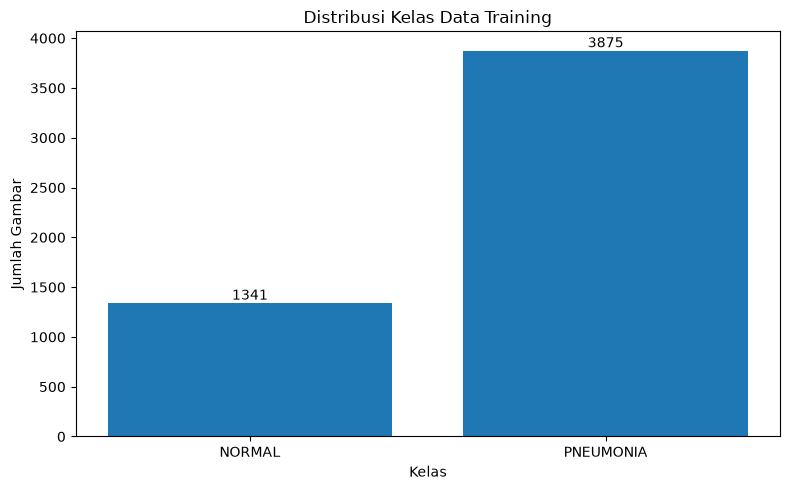

In [6]:
import matplotlib.pyplot as plt

class_names = ["NORMAL", "PNEUMONIA"]
class_counts = [normal_count, pneumonia_count]

plt.figure(figsize=(8, 5))

bars = plt.bar(class_names, class_counts)

plt.title("Distribusi Kelas Data Training")
plt.xlabel("Kelas")
plt.ylabel("Jumlah Gambar")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height)}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [7]:
# ============================================================
# 5. CEK UKURAN / RESOLUSI GAMBAR
# ============================================================

from PIL import Image

# Ambil beberapa gambar dari masing-masing kelas
normal_images = list((TRAIN_DIR / "NORMAL").glob("*"))
pneumonia_images = list((TRAIN_DIR / "PNEUMONIA").glob("*"))

print("Ukuran beberapa gambar NORMAL:")
for image_path in normal_images[:5]:
    with Image.open(image_path) as img:
        print(f"{image_path.name}: {img.size}")

print("\nUkuran beberapa gambar PNEUMONIA:")
for image_path in pneumonia_images[:5]:
    with Image.open(image_path) as img:
        print(f"{image_path.name}: {img.size}")

Ukuran beberapa gambar NORMAL:
IM-0115-0001.jpeg: (2090, 1858)
IM-0117-0001.jpeg: (1422, 1152)
IM-0119-0001.jpeg: (1810, 1434)
IM-0122-0001.jpeg: (1618, 1279)
IM-0125-0001.jpeg: (1600, 1125)

Ukuran beberapa gambar PNEUMONIA:
person1000_bacteria_2931.jpeg: (1152, 760)
person1000_virus_1681.jpeg: (1072, 768)
person1001_bacteria_2932.jpeg: (1244, 863)
person1002_bacteria_2933.jpeg: (1242, 940)
person1003_bacteria_2934.jpeg: (1488, 1280)


In [8]:
# ============================================================
# 6. CEK MODE / CHANNEL GAMBAR
# ============================================================

print("Mode beberapa gambar NORMAL:")
for image_path in normal_images[:5]:
    with Image.open(image_path) as img:
        print(f"{image_path.name}: mode={img.mode}")

print("\nMode beberapa gambar PNEUMONIA:")
for image_path in pneumonia_images[:5]:
    with Image.open(image_path) as img:
        print(f"{image_path.name}: mode={img.mode}")

Mode beberapa gambar NORMAL:
IM-0115-0001.jpeg: mode=L
IM-0117-0001.jpeg: mode=L
IM-0119-0001.jpeg: mode=L
IM-0122-0001.jpeg: mode=L
IM-0125-0001.jpeg: mode=L

Mode beberapa gambar PNEUMONIA:
person1000_bacteria_2931.jpeg: mode=L
person1000_virus_1681.jpeg: mode=L
person1001_bacteria_2932.jpeg: mode=L
person1002_bacteria_2933.jpeg: mode=L
person1003_bacteria_2934.jpeg: mode=L


In [9]:
# ============================================================
# 7. STATISTIK UKURAN GAMBAR
# ============================================================

import numpy as np

widths = []
heights = []

# Gabungkan gambar NORMAL dan PNEUMONIA
all_images = normal_images + pneumonia_images

for image_path in all_images:
    with Image.open(image_path) as img:
        width, height = img.size
        widths.append(width)
        heights.append(height)

print("Statistik ukuran gambar:")
print("-" * 40)

print(f"Jumlah gambar : {len(all_images)}")

print(f"\nLebar:")
print(f"  Minimum : {min(widths)}")
print(f"  Maximum : {max(widths)}")
print(f"  Rata-rata : {np.mean(widths):.2f}")

print(f"\nTinggi:")
print(f"  Minimum : {min(heights)}")
print(f"  Maximum : {max(heights)}")
print(f"  Rata-rata : {np.mean(heights):.2f}")

Statistik ukuran gambar:
----------------------------------------
Jumlah gambar : 5216

Lebar:
  Minimum : 384
  Maximum : 2916
  Rata-rata : 1320.61

Tinggi:
  Minimum : 127
  Maximum : 2663
  Rata-rata : 968.07


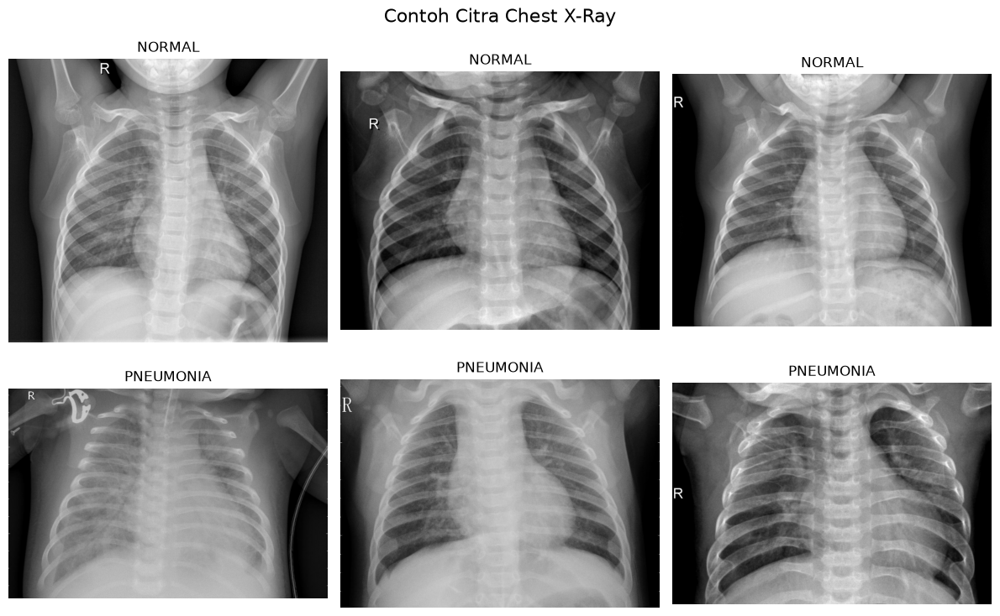

In [10]:
# ============================================================
# 8. VISUALISASI CONTOH GAMBAR
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

# Contoh NORMAL
for i, image_path in enumerate(normal_images[:3]):
    img = Image.open(image_path)

    axes[0, i].imshow(img, cmap="gray")
    axes[0, i].set_title("NORMAL")
    axes[0, i].axis("off")

# Contoh PNEUMONIA
for i, image_path in enumerate(pneumonia_images[:3]):
    img = Image.open(image_path)

    axes[1, i].imshow(img, cmap="gray")
    axes[1, i].set_title("PNEUMONIA")
    axes[1, i].axis("off")

plt.suptitle("Contoh Citra Chest X-Ray", fontsize=16)
plt.tight_layout()
plt.show()

In [11]:
# ============================================================
# 9. DISTRIBUSI INTENSITAS PIXEL
# ============================================================

# Ambil 1 gambar NORMAL dan 1 gambar PNEUMONIA
normal_sample = np.array(
    Image.open(normal_images[0]).convert("L")
)

pneumonia_sample = np.array(
    Image.open(pneumonia_images[0]).convert("L")
)

print("NORMAL")
print(f"Minimum pixel : {normal_sample.min()}")
print(f"Maximum pixel : {normal_sample.max()}")
print(f"Rata-rata pixel : {normal_sample.mean():.2f}")

print("\nPNEUMONIA")
print(f"Minimum pixel : {pneumonia_sample.min()}")
print(f"Maximum pixel : {pneumonia_sample.max()}")
print(f"Rata-rata pixel : {pneumonia_sample.mean():.2f}")

NORMAL
Minimum pixel : 0
Maximum pixel : 255
Rata-rata pixel : 128.91

PNEUMONIA
Minimum pixel : 0
Maximum pixel : 255
Rata-rata pixel : 114.54


In [12]:
# ============================================================
# 10. TRAIN - VALIDATION SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

# Semua gambar training
all_train_images = normal_images + pneumonia_images

# Label
all_labels = (
    ["NORMAL"] * len(normal_images)
    + ["PNEUMONIA"] * len(pneumonia_images)
)

# Split 80% training dan 20% validation
train_images, val_images, train_labels, val_labels = train_test_split(
    all_train_images,
    all_labels,
    test_size=0.20,
    random_state=42,
    stratify=all_labels
)

print("Hasil Train-Validation Split")
print("-" * 40)

print(f"Training   : {len(train_images)} gambar")
print(f"Validation : {len(val_images)} gambar")
print(f"Total      : {len(train_images) + len(val_images)} gambar")

Hasil Train-Validation Split
----------------------------------------
Training   : 4172 gambar
Validation : 1044 gambar
Total      : 5216 gambar


In [13]:
# ============================================================
# 11. CEK DISTRIBUSI KELAS SETELAH SPLIT
# ============================================================

from collections import Counter

train_distribution = Counter(train_labels)
val_distribution = Counter(val_labels)

print("Distribusi Training")
print("-" * 30)

for class_name, count in train_distribution.items():
    percentage = (count / len(train_labels)) * 100
    print(f"{class_name:<10}: {count} ({percentage:.2f}%)")

print("\nDistribusi Validation")
print("-" * 30)

for class_name, count in val_distribution.items():
    percentage = (count / len(val_labels)) * 100
    print(f"{class_name:<10}: {count} ({percentage:.2f}%)")

Distribusi Training
------------------------------
NORMAL    : 1073 (25.72%)
PNEUMONIA : 3099 (74.28%)

Distribusi Validation
------------------------------
PNEUMONIA : 776 (74.33%)
NORMAL    : 268 (25.67%)


In [14]:
# ============================================================
# 12. CEK PYTORCH DAN GPU
# ============================================================

import torch
import torchvision

print("PyTorch      :", torch.__version__)
print("Torchvision  :", torchvision.__version__)
print("CUDA tersedia:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU          :", torch.cuda.get_device_name(0))
    print("CUDA version :", torch.version.cuda)
else:
    print("GPU          : Tidak terdeteksi")

PyTorch      : 2.11.0+cu128
Torchvision  : 0.26.0+cu128
CUDA tersedia: True
GPU          : NVIDIA GeForce RTX 2050
CUDA version : 12.8


In [15]:
# ============================================================
# 13. DATASET DAN TRANSFORM
# ============================================================

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image


# ------------------------------------------------------------
# TRANSFORM TRAINING
# ------------------------------------------------------------

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    
    # Augmentasi ringan untuk X-Ray
    transforms.RandomHorizontalFlip(p=0.5),
    
    transforms.ToTensor(),
    
    # Normalisasi ImageNet
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ------------------------------------------------------------
# TRANSFORM VALIDATION
# ------------------------------------------------------------

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ------------------------------------------------------------
# CUSTOM DATASET
# ------------------------------------------------------------

class ChestXRayDataset(Dataset):

    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

        self.label_map = {
            "NORMAL": 0,
            "PNEUMONIA": 1
        }

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):

        image_path = self.image_paths[index]
        label_name = self.labels[index]

        # Buka gambar sebagai RGB agar kompatibel
        # dengan DenseNet121 pretrained ImageNet
        image = Image.open(image_path).convert("RGB")

        label = self.label_map[label_name]

        if self.transform:
            image = self.transform(image)

        return image, label

In [16]:
# ============================================================
# 14. MEMBUAT DATASET DAN DATALOADER
# ============================================================

# Dataset training
train_dataset = ChestXRayDataset(
    train_images,
    train_labels,
    transform=train_transform
)

# Dataset validation
val_dataset = ChestXRayDataset(
    val_images,
    val_labels,
    transform=val_transform
)

# Batch size
BATCH_SIZE = 16

# DataLoader training
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

# DataLoader validation
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Dataset dan DataLoader berhasil dibuat.")
print("-" * 45)
print(f"Training samples   : {len(train_dataset)}")
print(f"Validation samples : {len(val_dataset)}")
print(f"Batch size         : {BATCH_SIZE}")
print(f"Training batches   : {len(train_loader)}")
print(f"Validation batches : {len(val_loader)}")

Dataset dan DataLoader berhasil dibuat.
---------------------------------------------
Training samples   : 4172
Validation samples : 1044
Batch size         : 16
Training batches   : 261
Validation batches : 66


In [17]:
# ============================================================
# 15. SANITY CHECK DATALOADER
# ============================================================

images, labels = next(iter(train_loader))

print("Shape images :", images.shape)
print("Shape labels :", labels.shape)
print("Tipe images  :", images.dtype)
print("Tipe labels  :", labels.dtype)

print("\nLabel dalam batch:")
print(labels)

Shape images : torch.Size([16, 3, 224, 224])
Shape labels : torch.Size([16])
Tipe images  : torch.float32
Tipe labels  : torch.int64

Label dalam batch:
tensor([0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1])


In [18]:
# ============================================================
# 16. MEMBUAT MODEL DENSENET121
# ============================================================

import torch
import torch.nn as nn
from torchvision import models

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

# Load DenseNet121 pretrained ImageNet
model = models.densenet121(
    weights=models.DenseNet121_Weights.DEFAULT
)

# Freeze seluruh backbone
for param in model.features.parameters():
    param.requires_grad = False

# Jumlah fitur classifier DenseNet121
num_features = model.classifier.in_features

print("Jumlah fitur classifier:", num_features)

# Ganti classifier untuk binary classification
model.classifier = nn.Linear(
    num_features,
    1
)

# Pindahkan model ke GPU
model = model.to(device)

print("\nDenseNet121 berhasil dibuat.")

Device: cuda
Jumlah fitur classifier: 1024

DenseNet121 berhasil dibuat.


In [19]:
# ============================================================
# 17. CLASS WEIGHT DAN LOSS FUNCTION
# ============================================================

# Jumlah masing-masing kelas
normal_count = train_distribution["NORMAL"]
pneumonia_count = train_distribution["PNEUMONIA"]

total = normal_count + pneumonia_count

# Class weight
weight_normal = total / (2 * normal_count)
weight_pneumonia = total / (2 * pneumonia_count)

print("Class Weight")
print("-" * 30)
print(f"NORMAL    : {weight_normal:.4f}")
print(f"PNEUMONIA : {weight_pneumonia:.4f}")

# Weight untuk BCEWithLogitsLoss
# Karena output model adalah 1 logit,
# pos_weight digunakan untuk kelas positif (PNEUMONIA)
pos_weight = torch.tensor(
    [normal_count / pneumonia_count],
    dtype=torch.float32,
    device=device
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

print("\nLoss function:")
print(criterion)

Class Weight
------------------------------
NORMAL    : 1.9441
PNEUMONIA : 0.6731

Loss function:
BCEWithLogitsLoss()


In [20]:
# ============================================================
# 18. CLASSIFIER DAN WEIGHTED CROSS ENTROPY
# ============================================================

# Ganti classifier menjadi 2 output
model.classifier = nn.Linear(
    num_features,
    2
)

# Class weights
class_weights = torch.tensor(
    [weight_normal, weight_pneumonia],
    dtype=torch.float32,
    device=device
)

# Weighted Cross Entropy
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# Pastikan model berada di GPU
model = model.to(device)

print("Classifier:")
print(model.classifier)

print("\nClass weights:")
print(class_weights)

print("\nLoss function:")
print(criterion)

Classifier:
Linear(in_features=1024, out_features=2, bias=True)

Class weights:
tensor([1.9441, 0.6731], device='cuda:0')

Loss function:
CrossEntropyLoss()


In [21]:
# ============================================================
# 19. OPTIMIZER
# ============================================================

import torch.optim as optim

optimizer = optim.AdamW(
    model.classifier.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

print("Optimizer:")
print(optimizer)

Optimizer:
AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


In [22]:
# ============================================================
# 20. TEST FORWARD PASS
# ============================================================

model.eval()

images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

with torch.no_grad():
    outputs = model(images)
    loss = criterion(outputs, labels)

print("Device images :", images.device)
print("Device labels :", labels.device)
print("Output shape  :", outputs.shape)
print("Loss          :", loss.item())

Device images : cuda:0
Device labels : cuda:0
Output shape  : torch.Size([16, 2])
Loss          : 0.8021224737167358


In [23]:
# ============================================================
# 21. TRAINING LOOP
# ============================================================

NUM_EPOCHS = 10

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(NUM_EPOCHS):

    # ========================================================
    # TRAINING
    # ========================================================
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = torch.argmax(outputs, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_train_loss = running_loss / total
    epoch_train_accuracy = correct / total

    # ========================================================
    # VALIDATION
    # ========================================================
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_val_loss = running_loss / total
    epoch_val_accuracy = correct / total

    # Simpan history
    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    train_accuracies.append(epoch_train_accuracy)
    val_accuracies.append(epoch_val_accuracy)

    # Tampilkan hasil
    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] | "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Train Acc: {epoch_train_accuracy:.4f} | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Val Acc: {epoch_val_accuracy:.4f}"
    )

Epoch [1/10] | Train Loss: 0.3101 | Train Acc: 0.8830 | Val Loss: 0.1767 | Val Acc: 0.9301
Epoch [2/10] | Train Loss: 0.1939 | Train Acc: 0.9300 | Val Loss: 0.1493 | Val Acc: 0.9320
Epoch [3/10] | Train Loss: 0.1732 | Train Acc: 0.9384 | Val Loss: 0.1369 | Val Acc: 0.9377
Epoch [4/10] | Train Loss: 0.1674 | Train Acc: 0.9401 | Val Loss: 0.1513 | Val Acc: 0.9262
Epoch [5/10] | Train Loss: 0.1568 | Train Acc: 0.9449 | Val Loss: 0.1592 | Val Acc: 0.9167
Epoch [6/10] | Train Loss: 0.1500 | Train Acc: 0.9422 | Val Loss: 0.1181 | Val Acc: 0.9464
Epoch [7/10] | Train Loss: 0.1534 | Train Acc: 0.9437 | Val Loss: 0.1218 | Val Acc: 0.9425
Epoch [8/10] | Train Loss: 0.1512 | Train Acc: 0.9415 | Val Loss: 0.1129 | Val Acc: 0.9531
Epoch [9/10] | Train Loss: 0.1356 | Train Acc: 0.9465 | Val Loss: 0.1072 | Val Acc: 0.9540
Epoch [10/10] | Train Loss: 0.1529 | Train Acc: 0.9456 | Val Loss: 0.1102 | Val Acc: 0.9502


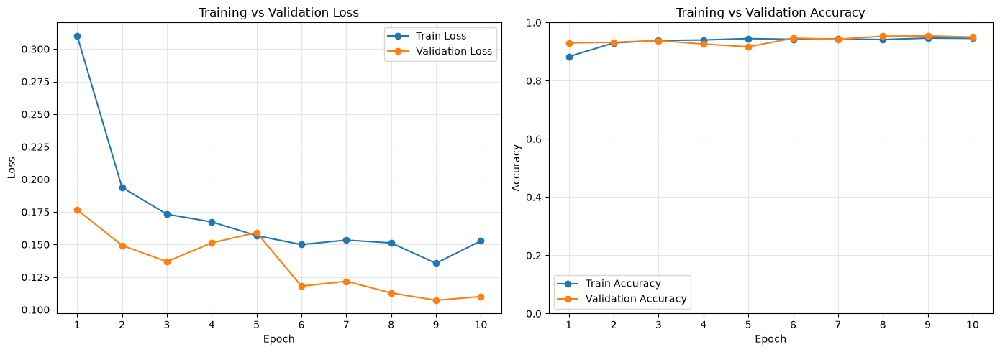

Epoch dengan validation loss terendah: 9
Validation loss terbaik: 0.1072
Validation accuracy pada epoch tersebut: 0.9540


In [24]:
# ============================================================
# 22. VISUALISASI TRAINING
# ============================================================

import matplotlib.pyplot as plt

epochs = range(1, NUM_EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Grafik Loss
axes[0].plot(
    epochs, train_losses,
    marker="o", label="Train Loss"
)
axes[0].plot(
    epochs, val_losses,
    marker="o", label="Validation Loss"
)
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_xticks(list(epochs))
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Grafik Accuracy
axes[1].plot(
    epochs, train_accuracies,
    marker="o", label="Train Accuracy"
)
axes[1].plot(
    epochs, val_accuracies,
    marker="o", label="Validation Accuracy"
)
axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_xticks(list(epochs))
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

best_epoch = min(
    range(NUM_EPOCHS),
    key=lambda i: val_losses[i]
) + 1

print("Epoch dengan validation loss terendah:", best_epoch)
print(f"Validation loss terbaik: {min(val_losses):.4f}")
print(f"Validation accuracy pada epoch tersebut: "
      f"{val_accuracies[best_epoch - 1]:.4f}")

In [25]:
# ============================================================
# 23. TEST DATASET DAN DATALOADER
# ============================================================

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_normal_images = list((TEST_DIR / "NORMAL").glob("*"))
test_pneumonia_images = list((TEST_DIR / "PNEUMONIA").glob("*"))

test_images = test_normal_images + test_pneumonia_images

test_labels = (
    ["NORMAL"] * len(test_normal_images)
    + ["PNEUMONIA"] * len(test_pneumonia_images)
)

test_dataset = ChestXRayDataset(
    test_images,
    test_labels,
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("Jumlah gambar test :", len(test_dataset))
print("NORMAL              :", len(test_normal_images))
print("PNEUMONIA           :", len(test_pneumonia_images))
print("Jumlah batch        :", len(test_loader))

Jumlah gambar test : 624
NORMAL              : 234
PNEUMONIA           : 390
Jumlah batch        : 39


In [26]:
# ============================================================
# 24. PREDIKSI PADA DATA TEST
# ============================================================

import torch
import numpy as np

model.eval()

y_true = []
y_pred = []
y_prob = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        # Probabilitas untuk kedua kelas
        probabilities = torch.softmax(outputs, dim=1)

        # Kelas dengan probabilitas tertinggi
        predictions = torch.argmax(outputs, dim=1)

        y_true.extend(labels.numpy().tolist())
        y_pred.extend(predictions.cpu().numpy().tolist())
        y_prob.extend(
            probabilities[:, 1].cpu().numpy().tolist()
        )

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

print("Prediksi selesai!")
print("Jumlah data dievaluasi :", len(y_true))
print("Jumlah prediksi NORMAL :", np.sum(y_pred == 0))
print("Jumlah prediksi PNEUMONIA:", np.sum(y_pred == 1))
print("Contoh label asli      :", y_true[:10])
print("Contoh prediksi        :", y_pred[:10])
print("Contoh probabilitas pneumonia:", y_prob[:5])

Prediksi selesai!
Jumlah data dievaluasi : 624
Jumlah prediksi NORMAL : 175
Jumlah prediksi PNEUMONIA: 449
Contoh label asli      : [0 0 0 0 0 0 0 0 0 0]
Contoh prediksi        : [0 0 0 1 0 0 0 1 0 0]
Contoh probabilitas pneumonia: [0.38955    0.21081057 0.17318423 0.78900397 0.10207064]


HASIL EVALUASI MODEL DENSENET121

Confusion Matrix:
[[166  68]
 [  9 381]]

Rincian:
True Negative  (TN): 166
False Positive (FP): 68
False Negative  (FN): 9
True Positive  (TP): 381

Metrik Evaluasi:
Accuracy     : 0.8766 (87.66%)
Sensitivity  : 0.9769 (97.69%)
Specificity  : 0.7094 (70.94%)
ROC-AUC      : 0.9497

Classification Report:
              precision    recall  f1-score   support

      NORMAL     0.9486    0.7094    0.8117       234
   PNEUMONIA     0.8486    0.9769    0.9082       390

    accuracy                         0.8766       624
   macro avg     0.8986    0.8432    0.8600       624
weighted avg     0.8861    0.8766    0.8720       624



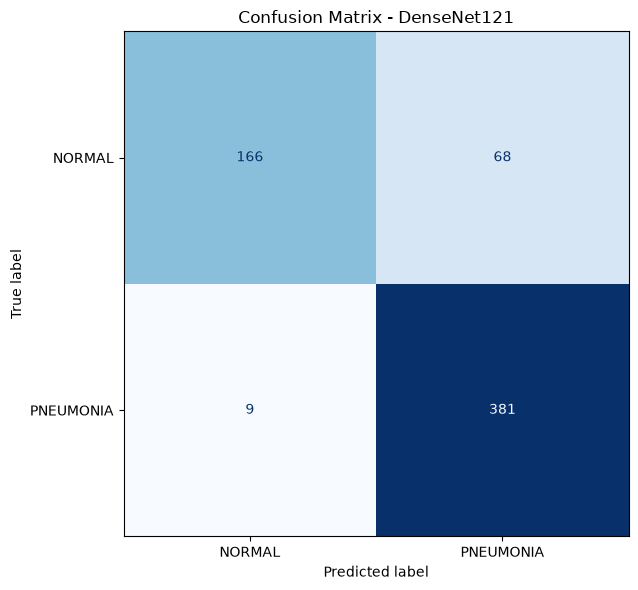

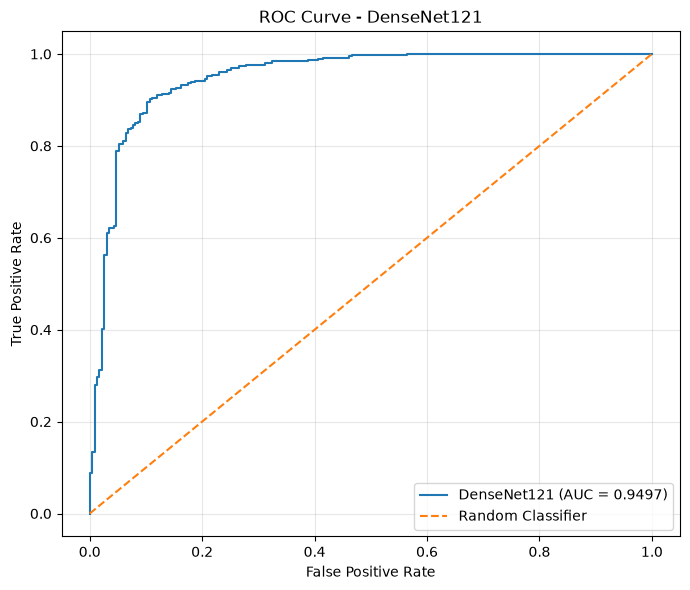

In [27]:
# ============================================================
# 25. EVALUASI MODEL PADA DATA TEST
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve
)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

tn, fp, fn, tp = cm.ravel()

# Metrik utama
accuracy = accuracy_score(y_true, y_pred)

specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0

auc = roc_auc_score(y_true, y_prob)

print("=" * 55)
print("HASIL EVALUASI MODEL DENSENET121")
print("=" * 55)

print("\nConfusion Matrix:")
print(cm)

print("\nRincian:")
print(f"True Negative  (TN): {tn}")
print(f"False Positive (FP): {fp}")
print(f"False Negative  (FN): {fn}")
print(f"True Positive  (TP): {tp}")

print("\nMetrik Evaluasi:")
print(f"Accuracy     : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Sensitivity  : {sensitivity:.4f} ({sensitivity * 100:.2f}%)")
print(f"Specificity  : {specificity:.4f} ({specificity * 100:.2f}%)")
print(f"ROC-AUC      : {auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["NORMAL", "PNEUMONIA"],
        digits=4,
        zero_division=0
    )
)

# Visualisasi confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "PNEUMONIA"]
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Confusion Matrix - DenseNet121")
plt.tight_layout()
plt.show()

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_true, y_prob)

plt.figure(figsize=(7, 6))
plt.plot(
    fpr,
    tpr,
    label=f"DenseNet121 (AUC = {auc:.4f})"
)
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - DenseNet121")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
# ============================================================
# 26. SIMPAN MODEL BASELINE
# ============================================================

from pathlib import Path
import torch

PROJECT_DIR = Path(r"D:\Lung disease detection")
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_path = MODEL_DIR / "densenet121_baseline.pth"

torch.save(
    {
        "model_name": "DenseNet121",
        "model_state_dict": model.state_dict(),
        "class_to_idx": {
            "NORMAL": 0,
            "PNEUMONIA": 1
        },
        "image_size": 224,
        "epoch": 10,
        "test_accuracy": float(accuracy),
        "test_sensitivity": float(sensitivity),
        "test_specificity": float(specificity),
        "test_roc_auc": float(auc)
    },
    checkpoint_path
)

print("Model baseline berhasil disimpan.")
print("Lokasi:", checkpoint_path)
print(f"Test accuracy: {accuracy:.4f}")
print(f"Test ROC-AUC : {auc:.4f}")

Model baseline berhasil disimpan.
Lokasi: D:\Lung disease detection\models\densenet121_baseline.pth
Test accuracy: 0.8766
Test ROC-AUC : 0.9497


In [30]:
# ============================================================
# 27. SIAPKAN MODEL UNTUK FINE-TUNING
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim

# Bekukan semua parameter terlebih dahulu
for param in model.features.parameters():
    param.requires_grad = False

# Buka blok terakhir DenseNet121
for param in model.features.denseblock4.parameters():
    param.requires_grad = True

for param in model.features.norm5.parameters():
    param.requires_grad = True

# Pastikan classifier tetap bisa dilatih
for param in model.classifier.parameters():
    param.requires_grad = True

# Optimizer dengan learning rate berbeda
optimizer = optim.AdamW(
    [
        {
            "params": model.features.denseblock4.parameters(),
            "lr": 0.0001
        },
        {
            "params": model.features.norm5.parameters(),
            "lr": 0.0001
        },
        {
            "params": model.classifier.parameters(),
            "lr": 0.001
        }
    ],
    weight_decay=0.0001
)

print("Model siap untuk fine-tuning.")
print("Device:", device)
print("Learning rate backbone: 0.0001")
print("Learning rate classifier: 0.001")

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

total_params = sum(p.numel() for p in model.parameters())

print(f"Parameter yang dilatih: {trainable_params:,}")
print(f"Total parameter model : {total_params:,}")

Model siap untuk fine-tuning.
Device: cuda
Learning rate backbone: 0.0001
Learning rate classifier: 0.001
Parameter yang dilatih: 2,162,178
Total parameter model : 6,955,906


In [40]:

import torch
import torch.nn as nn
import torch.optim as optim

# Bekukan seluruh backbone terlebih dahulu
for param in model.features.parameters():
    param.requires_grad = False

# Buka training untuk denseblock4
for param in model.features.denseblock4.parameters():
    param.requires_grad = True

# norm5 tetap dibekukan agar eksperimen lebih terkontrol
for param in model.features.norm5.parameters():
    param.requires_grad = False

# Classifier tetap dilatih
for param in model.classifier.parameters():
    param.requires_grad = True

# Optimizer dengan learning rate lebih kecil
optimizer = optim.AdamW(
    [
        {
            "params": model.features.denseblock4.parameters(),
            "lr": 0.00001
        },
        {
            "params": model.classifier.parameters(),
            "lr": 0.0001
        }
    ],
    weight_decay=0.0001
)

print("Setup fine-tuning diperbarui.")
print("Learning rate denseblock4: 0.00001")
print("Learning rate classifier: 0.0001")


Setup fine-tuning diperbarui.
Learning rate denseblock4: 0.00001
Learning rate classifier: 0.0001


In [41]:
# ============================================================
# 28. FINE-TUNING DENSENET121
# ============================================================

import copy
import torch
import torch.nn as nn
from pathlib import Path

NUM_FT_EPOCHS = 5

best_val_loss = float("inf")
best_model_state = copy.deepcopy(model.state_dict())

ft_train_losses = []
ft_val_losses = []
ft_train_accuracies = []
ft_val_accuracies = []

MODEL_DIR = Path(r"D:\Lung disease detection\models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

best_checkpoint_path = MODEL_DIR / "densenet121_finetuned_best.pth"

for epoch in range(NUM_FT_EPOCHS):

    # ---------------- TRAINING ----------------
    model.train()

    # Pertahankan BatchNorm backbone dalam mode evaluasi
    # agar statistik running-nya tidak berubah selama fine-tuning.
    model.features.eval()
    model.features.denseblock4.train()
    model.features.norm5.eval()
    model.classifier.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = torch.argmax(outputs, dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_train_loss = running_loss / total
    epoch_train_accuracy = correct / total

    # ---------------- VALIDATION ----------------
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_val_loss = running_loss / total
    epoch_val_accuracy = correct / total

    ft_train_losses.append(epoch_train_loss)
    ft_val_losses.append(epoch_val_loss)
    ft_train_accuracies.append(epoch_train_accuracy)
    ft_val_accuracies.append(epoch_val_accuracy)

    # Simpan checkpoint terbaik berdasarkan validation loss
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_model_state = copy.deepcopy(model.state_dict())

        torch.save(
            {
                "model_name": "DenseNet121",
                "model_state_dict": best_model_state,
                "class_to_idx": {
                    "NORMAL": 0,
                    "PNEUMONIA": 1
                },
                "image_size": 224,
                "epoch": epoch + 1,
                "val_loss": best_val_loss,
                "val_accuracy": epoch_val_accuracy
            },
            best_checkpoint_path
        )

        marker = " <-- best checkpoint"
    else:
        marker = ""

    print(
        f"FT Epoch [{epoch + 1}/{NUM_FT_EPOCHS}] | "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Train Acc: {epoch_train_accuracy:.4f} | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Val Acc: {epoch_val_accuracy:.4f}"
        f"{marker}"
    )

# Pulihkan bobot terbaik untuk penggunaan selanjutnya
model.load_state_dict(best_model_state)

print("\nFine-tuning selesai.")
print(f"Best validation loss: {best_val_loss:.4f}")
print("Checkpoint:", best_checkpoint_path)

FT Epoch [1/5] | Train Loss: 0.1053 | Train Acc: 0.9626 | Val Loss: 0.0965 | Val Acc: 0.9617 <-- best checkpoint
FT Epoch [2/5] | Train Loss: 0.0820 | Train Acc: 0.9688 | Val Loss: 0.0843 | Val Acc: 0.9646 <-- best checkpoint
FT Epoch [3/5] | Train Loss: 0.0777 | Train Acc: 0.9724 | Val Loss: 0.0813 | Val Acc: 0.9732 <-- best checkpoint
FT Epoch [4/5] | Train Loss: 0.0588 | Train Acc: 0.9808 | Val Loss: 0.0821 | Val Acc: 0.9626
FT Epoch [5/5] | Train Loss: 0.0449 | Train Acc: 0.9849 | Val Loss: 0.0729 | Val Acc: 0.9732 <-- best checkpoint

Fine-tuning selesai.
Best validation loss: 0.0729
Checkpoint: D:\Lung disease detection\models\densenet121_finetuned_best.pth


HASIL EVALUASI DENSENET121 FINE-TUNED
Checkpoint epoch : 5
Validation loss  : 0.0729
Validation acc   : 0.9732

Confusion Matrix:
[[139  95]
 [  2 388]]

Metrik Test:
Accuracy    : 0.8446 (84.46%)
Sensitivity : 0.9949 (99.49%)
Specificity : 0.5940 (59.40%)
ROC-AUC     : 0.9532

Classification Report:
              precision    recall  f1-score   support

      NORMAL     0.9858    0.5940    0.7413       234
   PNEUMONIA     0.8033    0.9949    0.8889       390

    accuracy                         0.8446       624
   macro avg     0.8946    0.7944    0.8151       624
weighted avg     0.8718    0.8446    0.8336       624



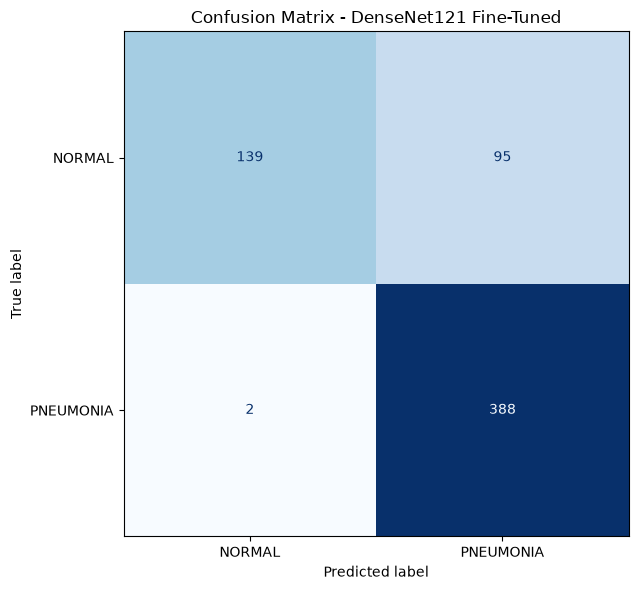

In [42]:
# ============================================================
# 29. EVALUASI MODEL FINE-TUNED PADA DATA TEST
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    roc_auc_score,
    ConfusionMatrixDisplay
)

# Muat checkpoint terbaik
checkpoint = torch.load(
    best_checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

# Prediksi seluruh data test
y_true_ft = []
y_pred_ft = []
y_prob_ft = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)
        predictions = torch.argmax(outputs, dim=1)

        y_true_ft.extend(labels.numpy().tolist())
        y_pred_ft.extend(predictions.cpu().numpy().tolist())
        y_prob_ft.extend(
            probabilities[:, 1].cpu().numpy().tolist()
        )

y_true_ft = np.array(y_true_ft)
y_pred_ft = np.array(y_pred_ft)
y_prob_ft = np.array(y_prob_ft)

# Hitung metrik
cm_ft = confusion_matrix(
    y_true_ft, y_pred_ft, labels=[0, 1]
)

tn, fp, fn, tp = cm_ft.ravel()

accuracy_ft = accuracy_score(y_true_ft, y_pred_ft)
sensitivity_ft = tp / (tp + fn) if (tp + fn) else 0
specificity_ft = tn / (tn + fp) if (tn + fp) else 0
auc_ft = roc_auc_score(y_true_ft, y_prob_ft)

print("=" * 55)
print("HASIL EVALUASI DENSENET121 FINE-TUNED")
print("=" * 55)

print(f"Checkpoint epoch : {checkpoint['epoch']}")
print(f"Validation loss  : {checkpoint['val_loss']:.4f}")
print(f"Validation acc   : {checkpoint['val_accuracy']:.4f}")

print("\nConfusion Matrix:")
print(cm_ft)

print("\nMetrik Test:")
print(f"Accuracy    : {accuracy_ft:.4f} ({accuracy_ft * 100:.2f}%)")
print(f"Sensitivity : {sensitivity_ft:.4f} ({sensitivity_ft * 100:.2f}%)")
print(f"Specificity : {specificity_ft:.4f} ({specificity_ft * 100:.2f}%)")
print(f"ROC-AUC     : {auc_ft:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true_ft,
    y_pred_ft,
    labels=[0, 1],
    target_names=["NORMAL", "PNEUMONIA"],
    digits=4,
    zero_division=0
))

# Visualisasi confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_ft,
    display_labels=["NORMAL", "PNEUMONIA"]
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)
ax.set_title("Confusion Matrix - DenseNet121 Fine-Tuned")
plt.tight_layout()
plt.show()

In [43]:
# ============================================================
# 30. PERBANDINGAN VALIDATION SET
# ============================================================

import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)
from torchvision import models
import torch.nn as nn

def predict_loader(model, loader, device):
    model.eval()
    labels_all = []
    preds_all = []
    probs_all = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)

            labels_all.extend(labels.numpy().tolist())
            preds_all.extend(
                outputs.argmax(dim=1).cpu().numpy().tolist()
            )
            probs_all.extend(
                probs[:, 1].cpu().numpy().tolist()
            )

    return (
        np.array(labels_all),
        np.array(preds_all),
        np.array(probs_all)
    )

# Simpan hasil model fine-tuned pada validation set
y_val_true, y_val_ft_pred, y_val_ft_prob = predict_loader(
    model, val_loader, device
)

print("FINE-TUNED - VALIDATION")
print("Accuracy:", round(
    accuracy_score(y_val_true, y_val_ft_pred), 4
))
print("Confusion matrix:")
print(confusion_matrix(y_val_true, y_val_ft_pred))
print(classification_report(
    y_val_true,
    y_val_ft_pred,
    labels=[0, 1],
    target_names=["NORMAL", "PNEUMONIA"],
    digits=4,
    zero_division=0
))
print("ROC-AUC:", round(
    roc_auc_score(y_val_true, y_val_ft_prob), 4
))

FINE-TUNED - VALIDATION
Accuracy: 0.9732
Confusion matrix:
[[263   5]
 [ 23 753]]
              precision    recall  f1-score   support

      NORMAL     0.9196    0.9813    0.9495       268
   PNEUMONIA     0.9934    0.9704    0.9817       776

    accuracy                         0.9732      1044
   macro avg     0.9565    0.9759    0.9656      1044
weighted avg     0.9745    0.9732    0.9735      1044

ROC-AUC: 0.9967


In [35]:
# ============================================================
# 31. ANALISIS THRESHOLD PADA VALIDATION SET
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, roc_auc_score

thresholds = np.arange(0.30, 0.81, 0.05)
threshold_results = []

for threshold in thresholds:
    predictions = (y_val_ft_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn) if (tp + fn) else 0
    specificity = tn / (tn + fp) if (tn + fp) else 0
    accuracy = (tp + tn) / (tp + tn + fp + fn)

    threshold_results.append({
        "Threshold": round(float(threshold), 2),
        "Accuracy": round(accuracy, 4),
        "Sensitivity": round(sensitivity, 4),
        "Specificity": round(specificity, 4),
        "FP": int(fp),
        "FN": int(fn)
    })

threshold_df = pd.DataFrame(threshold_results)

print("Analisis threshold pada validation set:")
display(threshold_df)

Analisis threshold pada validation set:


,Threshold,Accuracy,Sensitivity,Specificity,FP,FN
0,0.30,0.9875,0.9923,0.9739,7,6
1,0.35,0.9875,0.9923,0.9739,7,6
2,0.40,0.9875,0.9923,0.9739,7,6
3,0.45,0.9885,0.9910,0.9813,5,7
4,0.50,0.9895,0.9910,0.9851,4,7
5,0.55,0.9895,0.9910,0.9851,4,7
6,0.60,0.9875,0.9884,0.9851,4,9
7,0.65,0.9866,0.9871,0.9851,4,10
8,0.70,0.9856,0.9858,0.9851,4,11
9,0.75,0.9847,0.9832,0.9888,3,13


In [36]:
# ============================================================
# 32. TETAPKAN THRESHOLD MODEL
# ============================================================

BEST_THRESHOLD = 0.50

val_predictions = (
    y_val_ft_prob >= BEST_THRESHOLD
).astype(int)

from sklearn.metrics import classification_report, confusion_matrix

print("Threshold yang dipilih:", BEST_THRESHOLD)
print("\nConfusion Matrix Validation:")
print(confusion_matrix(y_val_true, val_predictions))

print("\nClassification Report Validation:")
print(classification_report(
    y_val_true,
    val_predictions,
    labels=[0, 1],
    target_names=["NORMAL", "PNEUMONIA"],
    digits=4,
    zero_division=0
))

Threshold yang dipilih: 0.5

Confusion Matrix Validation:
[[264   4]
 [  7 769]]

Classification Report Validation:
              precision    recall  f1-score   support

      NORMAL     0.9742    0.9851    0.9796       268
   PNEUMONIA     0.9948    0.9910    0.9929       776

    accuracy                         0.9895      1044
   macro avg     0.9845    0.9880    0.9862      1044
weighted avg     0.9895    0.9895    0.9895      1044



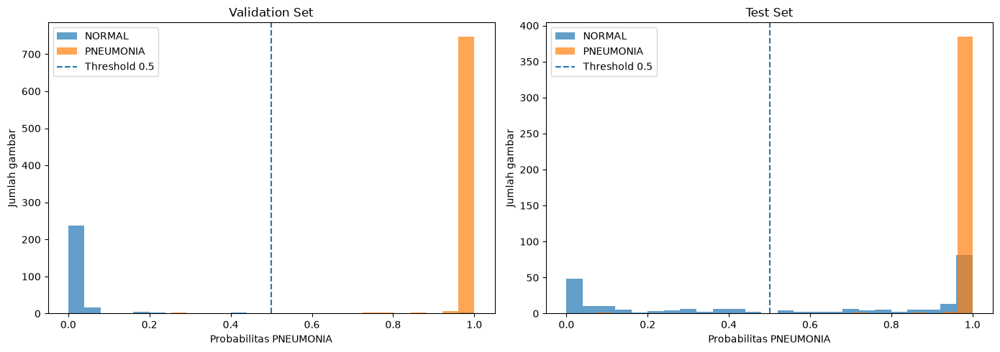

In [37]:
# ============================================================
# 33. ANALISIS PROBABILITAS VALIDATION VS TEST
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Validation set
axes[0].hist(
    y_val_ft_prob[y_val_true == 0],
    bins=25,
    alpha=0.7,
    label="NORMAL"
)
axes[0].hist(
    y_val_ft_prob[y_val_true == 1],
    bins=25,
    alpha=0.7,
    label="PNEUMONIA"
)
axes[0].axvline(
    0.5, linestyle="--", label="Threshold 0.5"
)
axes[0].set_title("Validation Set")
axes[0].set_xlabel("Probabilitas PNEUMONIA")
axes[0].set_ylabel("Jumlah gambar")
axes[0].legend()

# Test set
axes[1].hist(
    y_prob_ft[y_true_ft == 0],
    bins=25,
    alpha=0.7,
    label="NORMAL"
)
axes[1].hist(
    y_prob_ft[y_true_ft == 1],
    bins=25,
    alpha=0.7,
    label="PNEUMONIA"
)
axes[1].axvline(
    0.5, linestyle="--", label="Threshold 0.5"
)
axes[1].set_title("Test Set")
axes[1].set_xlabel("Probabilitas PNEUMONIA")
axes[1].set_ylabel("Jumlah gambar")
axes[1].legend()

plt.tight_layout()
plt.show()

In [38]:
# Evaluasi model baseline pada validation set

import torch
import numpy as np
from pathlib import Path

baseline_path = Path(
    r"D:\Lung disease detection\models\densenet121_baseline.pth"
)

# Muat kembali bobot baseline
baseline_checkpoint = torch.load(
    baseline_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(baseline_checkpoint["model_state_dict"])

# Prediksi validation set
y_val_true, y_val_base_pred, y_val_base_prob = predict_loader(
    model, val_loader, device
)

# Hitung confusion matrix baseline
from sklearn.metrics import confusion_matrix, classification_report

print("CONFUSION MATRIX - BASELINE")
print(confusion_matrix(y_val_true, y_val_base_pred))

print("\nCLASSIFICATION REPORT - BASELINE")
print(
    classification_report(
        y_val_true,
        y_val_base_pred,
        target_names=["NORMAL", "PNEUMONIA"],
        digits=4
    )
)

CONFUSION MATRIX - BASELINE
[[261   7]
 [ 45 731]]

CLASSIFICATION REPORT - BASELINE
              precision    recall  f1-score   support

      NORMAL     0.8529    0.9739    0.9094       268
   PNEUMONIA     0.9905    0.9420    0.9657       776

    accuracy                         0.9502      1044
   macro avg     0.9217    0.9579    0.9375      1044
weighted avg     0.9552    0.9502    0.9512      1044



In [39]:

# Evaluasi ulang baseline pada test set

model.load_state_dict(baseline_checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

y_true_base_test, y_pred_base_test, y_prob_base_test = predict_loader(
    model, test_loader, device
)

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    roc_auc_score
)

print("CONFUSION MATRIX - BASELINE TEST")
print(confusion_matrix(y_true_base_test, y_pred_base_test))

print("\nCLASSIFICATION REPORT - BASELINE TEST")
print(
    classification_report(
        y_true_base_test,
        y_pred_base_test,
        target_names=["NORMAL", "PNEUMONIA"],
        digits=4
    )
)

print("Accuracy:", round(accuracy_score(
    y_true_base_test, y_pred_base_test
), 4))

print("ROC-AUC:", round(roc_auc_score(
    y_true_base_test, y_prob_base_test
), 4))


CONFUSION MATRIX - BASELINE TEST
[[166  68]
 [  9 381]]

CLASSIFICATION REPORT - BASELINE TEST
              precision    recall  f1-score   support

      NORMAL     0.9486    0.7094    0.8117       234
   PNEUMONIA     0.8486    0.9769    0.9082       390

    accuracy                         0.8766       624
   macro avg     0.8986    0.8432    0.8600       624
weighted avg     0.8861    0.8766    0.8720       624

Accuracy: 0.8766
ROC-AUC: 0.9497


In [44]:

# Evaluasi checkpoint fine-tuning terbaru pada test set

import torch
import numpy as np
from pathlib import Path
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    roc_auc_score
)

checkpoint_path = Path(
    r"D:\Lung disease detection\models\densenet121_finetuned_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

y_true_ft_new, y_pred_ft_new, y_prob_ft_new = predict_loader(
    model, test_loader, device
)

print("Checkpoint epoch:", checkpoint["epoch"])
print("Validation loss:", round(checkpoint["val_loss"], 4))
print("Validation accuracy:", round(checkpoint["val_accuracy"], 4))

print("\nCONFUSION MATRIX - FINE-TUNED TEST")
print(confusion_matrix(y_true_ft_new, y_pred_ft_new))

print("\nCLASSIFICATION REPORT - FINE-TUNED TEST")
print(
    classification_report(
        y_true_ft_new,
        y_pred_ft_new,
        target_names=["NORMAL", "PNEUMONIA"],
        digits=4
    )
)

print("Accuracy:", round(
    accuracy_score(y_true_ft_new, y_pred_ft_new), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_true_ft_new, y_prob_ft_new), 4
))


Checkpoint epoch: 5
Validation loss: 0.0729
Validation accuracy: 0.9732

CONFUSION MATRIX - FINE-TUNED TEST
[[139  95]
 [  2 388]]

CLASSIFICATION REPORT - FINE-TUNED TEST
              precision    recall  f1-score   support

      NORMAL     0.9858    0.5940    0.7413       234
   PNEUMONIA     0.8033    0.9949    0.8889       390

    accuracy                         0.8446       624
   macro avg     0.8946    0.7944    0.8151       624
weighted avg     0.8718    0.8446    0.8336       624

Accuracy: 0.8446
ROC-AUC: 0.9532


In [45]:

# Periksa preprocessing dan pemetaan label

print("Label map pada Dataset:")
print(test_dataset.label_map)

print("\nTransformasi validation:")
print(val_transform)

print("\nTransformasi test:")
print(test_transform)

print("\nJumlah validation:", len(val_dataset))
print("Jumlah test:", len(test_dataset))

print("\nJumlah label test:")
from collections import Counter
print(Counter(test_labels))


Label map pada Dataset:
{'NORMAL': 0, 'PNEUMONIA': 1}

Transformasi validation:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Transformasi test:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Jumlah validation: 1044
Jumlah test: 624

Jumlah label test:
Counter({'PNEUMONIA': 390, 'NORMAL': 234})


VALIDATION
Jumlah gambar: 1044
Rata-rata lebar: 1338.09
Rata-rata tinggi: 988.06
Median lebar: 1296.0
Median tinggi: 896.0

TEST
Jumlah gambar: 624
Rata-rata lebar: 1388.13
Rata-rata tinggi: 991.71
Median lebar: 1265.0
Median tinggi: 870.5


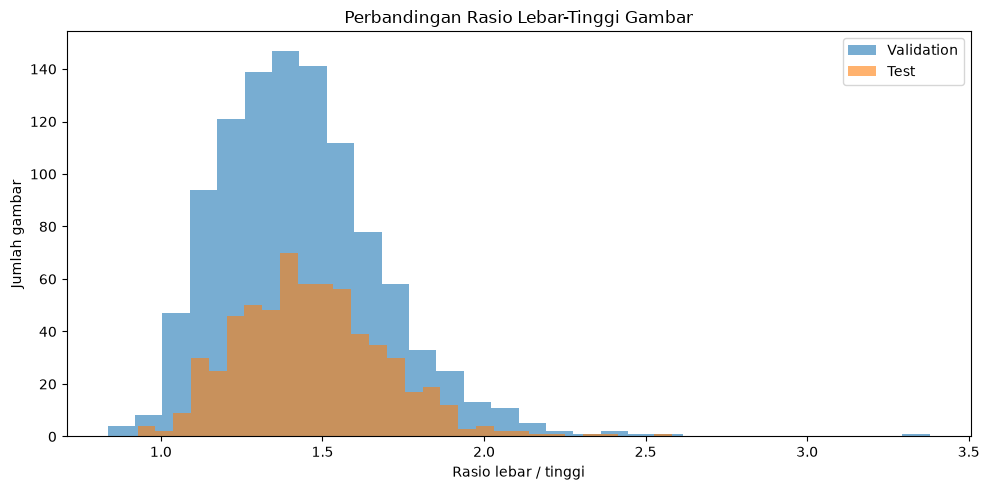

In [46]:

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

def get_image_dimensions(image_paths):
    dimensions = []

    for path in image_paths:
        try:
            with Image.open(path) as img:
                width, height = img.size
                dimensions.append((width, height))
        except Exception as e:
            print(f"Gagal membaca {path}: {e}")

    return np.array(dimensions)

val_dimensions = get_image_dimensions(val_images)
test_dimensions = get_image_dimensions(test_images)

print("VALIDATION")
print("Jumlah gambar:", len(val_dimensions))
print("Rata-rata lebar:", round(val_dimensions[:, 0].mean(), 2))
print("Rata-rata tinggi:", round(val_dimensions[:, 1].mean(), 2))
print("Median lebar:", round(np.median(val_dimensions[:, 0]), 2))
print("Median tinggi:", round(np.median(val_dimensions[:, 1]), 2))

print("\nTEST")
print("Jumlah gambar:", len(test_dimensions))
print("Rata-rata lebar:", round(test_dimensions[:, 0].mean(), 2))
print("Rata-rata tinggi:", round(test_dimensions[:, 1].mean(), 2))
print("Median lebar:", round(np.median(test_dimensions[:, 0]), 2))
print("Median tinggi:", round(np.median(test_dimensions[:, 1]), 2))

plt.figure(figsize=(10, 5))

plt.hist(
    val_dimensions[:, 0] / val_dimensions[:, 1],
    bins=30,
    alpha=0.6,
    label="Validation"
)
plt.hist(
    test_dimensions[:, 0] / test_dimensions[:, 1],
    bins=30,
    alpha=0.6,
    label="Test"
)

plt.title("Perbandingan Rasio Lebar-Tinggi Gambar")
plt.xlabel("Rasio lebar / tinggi")
plt.ylabel("Jumlah gambar")
plt.legend()
plt.tight_layout()
plt.show()


VALIDATION
Rata-rata intensitas: 122.94
Median intensitas: 123.05

TEST
Rata-rata intensitas: 121.04
Median intensitas: 121.14


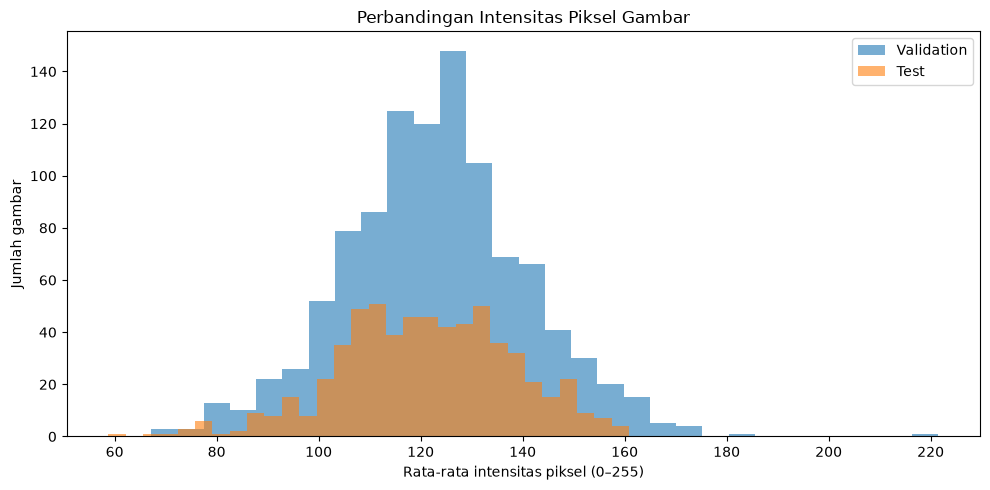

In [47]:

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

def get_mean_brightness(image_paths):
    brightness = []

    for path in image_paths:
        try:
            with Image.open(path) as img:
                gray = img.convert("L")
                brightness.append(
                    np.asarray(gray, dtype=np.float32).mean()
                )
        except Exception as e:
            print(f"Gagal membaca {path}: {e}")

    return np.array(brightness)

val_brightness = get_mean_brightness(val_images)
test_brightness = get_mean_brightness(test_images)

print("VALIDATION")
print("Rata-rata intensitas:", round(val_brightness.mean(), 2))
print("Median intensitas:", round(np.median(val_brightness), 2))

print("\nTEST")
print("Rata-rata intensitas:", round(test_brightness.mean(), 2))
print("Median intensitas:", round(np.median(test_brightness), 2))

plt.figure(figsize=(10, 5))

plt.hist(
    val_brightness,
    bins=30,
    alpha=0.6,
    label="Validation"
)
plt.hist(
    test_brightness,
    bins=30,
    alpha=0.6,
    label="Test"
)

plt.title("Perbandingan Intensitas Piksel Gambar")
plt.xlabel("Rata-rata intensitas piksel (0–255)")
plt.ylabel("Jumlah gambar")
plt.legend()
plt.tight_layout()
plt.show()


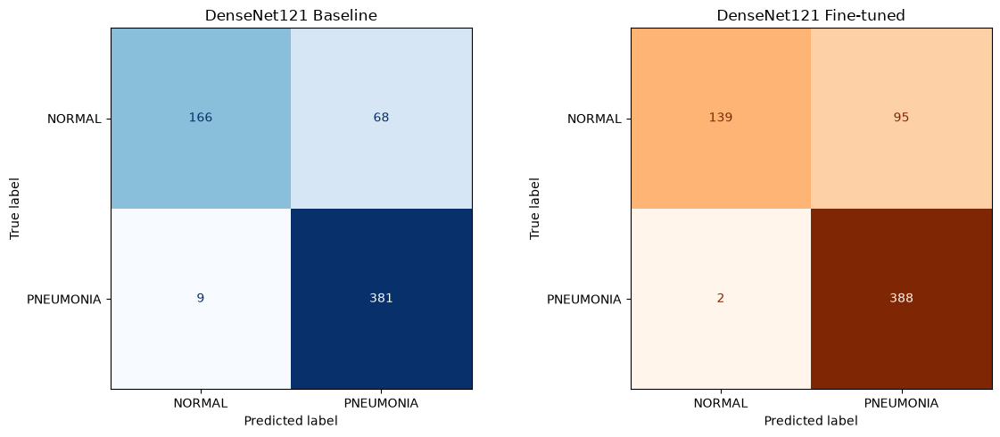

In [48]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Prediksi baseline dan fine-tuned sudah tersimpan
cm_baseline = confusion_matrix(
    y_true_base_test,
    y_pred_base_test
)

cm_finetuned = confusion_matrix(
    y_true_ft_new,
    y_pred_ft_new
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_baseline,
    display_labels=["NORMAL", "PNEUMONIA"]
).plot(
    ax=axes[0],
    cmap="Blues",
    colorbar=False
)
axes[0].set_title("DenseNet121 Baseline")

ConfusionMatrixDisplay(
    confusion_matrix=cm_finetuned,
    display_labels=["NORMAL", "PNEUMONIA"]
).plot(
    ax=axes[1],
    cmap="Oranges",
    colorbar=False
)
axes[1].set_title("DenseNet121 Fine-tuned")

plt.tight_layout()
plt.show()


In [49]:

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Pastikan probabilitas validation kedua model sudah tersimpan:
# y_val_base_prob dan y_val_ft_prob
# y_val_true adalah label sebenarnya validation

thresholds = np.arange(0.30, 0.81, 0.05)
results = []

for model_name, probabilities in [
    ("Baseline", y_val_base_prob),
    ("Fine-tuned", y_val_ft_prob)
]:
    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val_true, predictions, labels=[0, 1]
        ).ravel()

        results.append({
            "Model": model_name,
            "Threshold": round(float(threshold), 2),
            "Accuracy": round((tn + tp) / (tn + fp + fn + tp), 4),
            "Sensitivity": round(tp / (tp + fn), 4),
            "Specificity": round(tn / (tn + fp), 4),
            "FP": int(fp),
            "FN": int(fn)
        })

threshold_results = pd.DataFrame(results)
display(threshold_results)


,Model,Threshold,Accuracy,Sensitivity,Specificity,FP,FN
0,Baseline,0.30,0.9636,0.9639,0.9627,10,28
1,Baseline,0.35,0.9607,0.9575,0.9701,8,33
2,Baseline,0.40,0.9579,0.9536,0.9701,8,36
3,Baseline,0.45,0.9559,0.9497,0.9739,7,39
4,Baseline,0.50,0.9502,0.9420,0.9739,7,45
5,Baseline,0.55,0.9502,0.9394,0.9813,5,47
6,Baseline,0.60,0.9454,0.9317,0.9851,4,53
7,Baseline,0.65,0.9358,0.9175,0.9888,3,64
8,Baseline,0.70,0.9291,0.9085,0.9888,3,71
9,Baseline,0.75,0.9224,0.8995,0.9888,3,78


In [50]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    roc_auc_score
)
import numpy as np

# Probabilitas dari checkpoint fine-tuned terbaru
# y_true_ft_new dan y_prob_ft_new harus berasal dari evaluasi
# checkpoint fine-tuned terbaru pada test set.

BEST_THRESHOLD = 0.35

y_pred_ft_threshold = (
    y_prob_ft_new >= BEST_THRESHOLD
).astype(int)

print("Threshold:", BEST_THRESHOLD)

print("\nCONFUSION MATRIX - FINE-TUNED TEST")
print(
    confusion_matrix(
        y_true_ft_new,
        y_pred_ft_threshold,
        labels=[0, 1]
    )
)

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_true_ft_new,
        y_pred_ft_threshold,
        labels=[0, 1],
        target_names=["NORMAL", "PNEUMONIA"],
        digits=4
    )
)

print(
    "Accuracy:",
    round(
        accuracy_score(y_true_ft_new, y_pred_ft_threshold),
        4
    )
)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(y_true_ft_new, y_prob_ft_new),
        4
    )
)


Threshold: 0.35

CONFUSION MATRIX - FINE-TUNED TEST
[[126 108]
 [  1 389]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      NORMAL     0.9921    0.5385    0.6981       234
   PNEUMONIA     0.7827    0.9974    0.8771       390

    accuracy                         0.8253       624
   macro avg     0.8874    0.7679    0.7876       624
weighted avg     0.8612    0.8253    0.8100       624

Accuracy: 0.8253
ROC-AUC: 0.9532


In [51]:

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch

# Cari gambar NORMAL yang salah diprediksi sebagai PNEUMONIA
# Label: NORMAL = 0, PNEUMONIA = 1

baseline_fp_idx = np.where(
    (y_true_base_test == 0) &
    (y_pred_base_test == 1)
)[0]

finetuned_fp_idx = np.where(
    (y_true_ft_new == 0) &
    (y_pred_ft_new == 1)
)[0]

print("Baseline false positive:", len(baseline_fp_idx))
print("Fine-tuned false positive:", len(finetuned_fp_idx))

print("\nContoh indeks baseline:", baseline_fp_idx[:10])
print("Contoh indeks fine-tuned:", finetuned_fp_idx[:10])


Baseline false positive: 68
Fine-tuned false positive: 95

Contoh indeks baseline: [ 3  7 14 16 26 45 47 48 50 52]
Contoh indeks fine-tuned: [ 0  3  7 11 14 16 21 26 40 44]


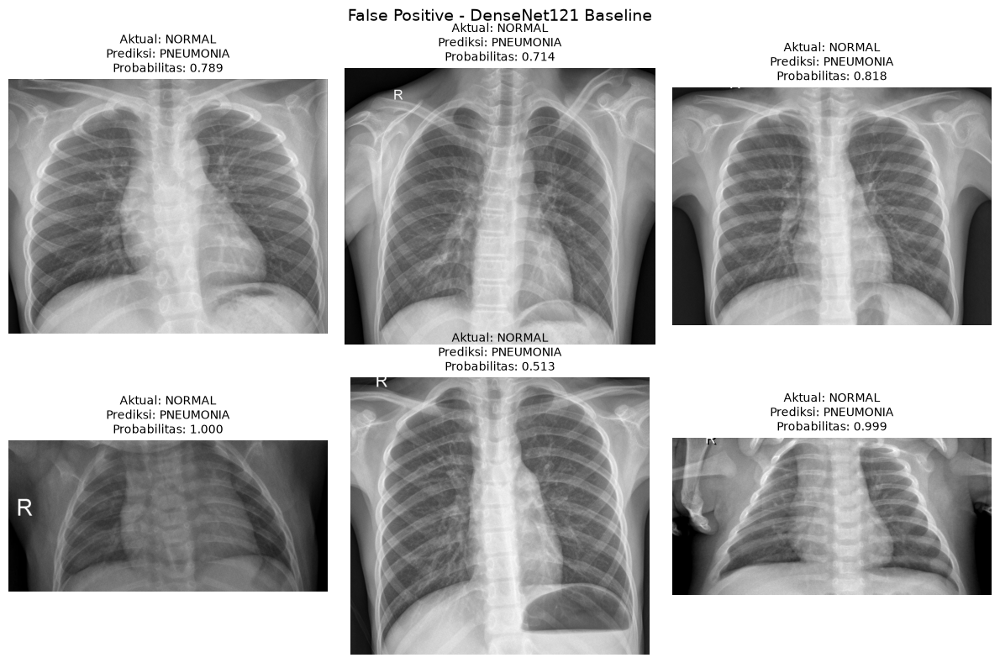

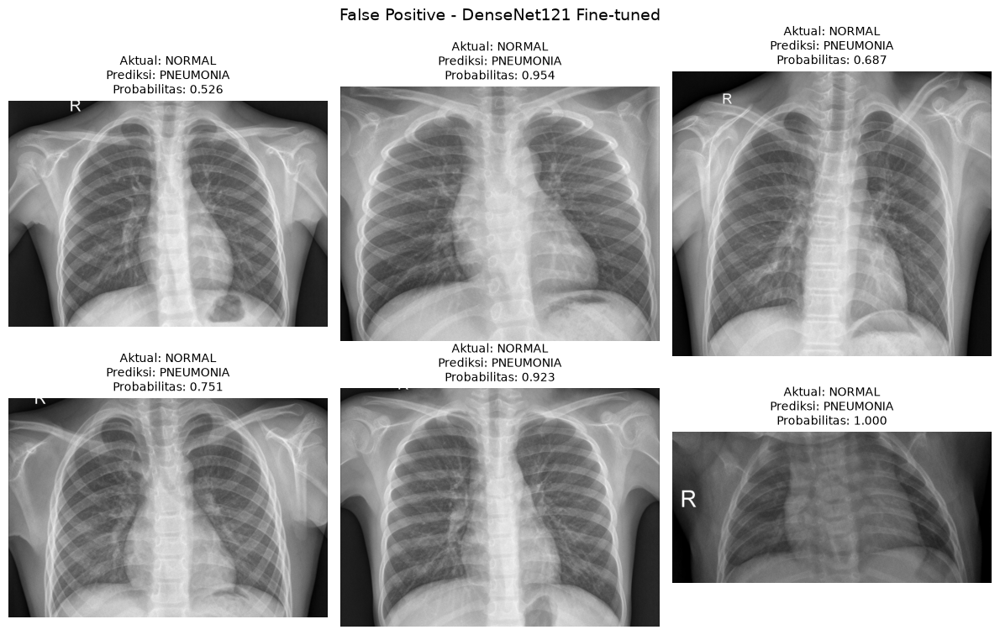

In [52]:

def show_false_positives(indices, probabilities, title, max_images=6):
    selected = indices[:max_images]

    if len(selected) == 0:
        print(f"Tidak ada false positive pada {title}.")
        return

    fig, axes = plt.subplots(
        2, 3, figsize=(12, 8)
    )
    axes = axes.flatten()

    for ax in axes:
        ax.axis("off")

    for ax, idx in zip(axes, selected):
        image_path = test_images[idx]

        with Image.open(image_path) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(
            f"Aktual: NORMAL\n"
            f"Prediksi: PNEUMONIA\n"
            f"Probabilitas: {probabilities[idx]:.3f}",
            fontsize=10
        )
        ax.axis("off")

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


show_false_positives(
    baseline_fp_idx,
    y_prob_base_test,
    "False Positive - DenseNet121 Baseline"
)

show_false_positives(
    finetuned_fp_idx,
    y_prob_ft_new,
    "False Positive - DenseNet121 Fine-tuned"
)


In [53]:

# Bandingkan false positive baseline dan fine-tuned

baseline_fp_set = set(baseline_fp_idx.tolist())
finetuned_fp_set = set(finetuned_fp_idx.tolist())

common_fp = sorted(baseline_fp_set & finetuned_fp_set)
baseline_only_fp = sorted(baseline_fp_set - finetuned_fp_set)
finetuned_only_fp = sorted(finetuned_fp_set - baseline_fp_set)

print("False positive baseline:", len(baseline_fp_set))
print("False positive fine-tuned:", len(finetuned_fp_set))
print("Salah pada kedua model:", len(common_fp))
print("Hanya baseline yang salah:", len(baseline_only_fp))
print("Hanya fine-tuned yang salah:", len(finetuned_only_fp))


False positive baseline: 68
False positive fine-tuned: 95
Salah pada kedua model: 67
Hanya baseline yang salah: 1
Hanya fine-tuned yang salah: 28


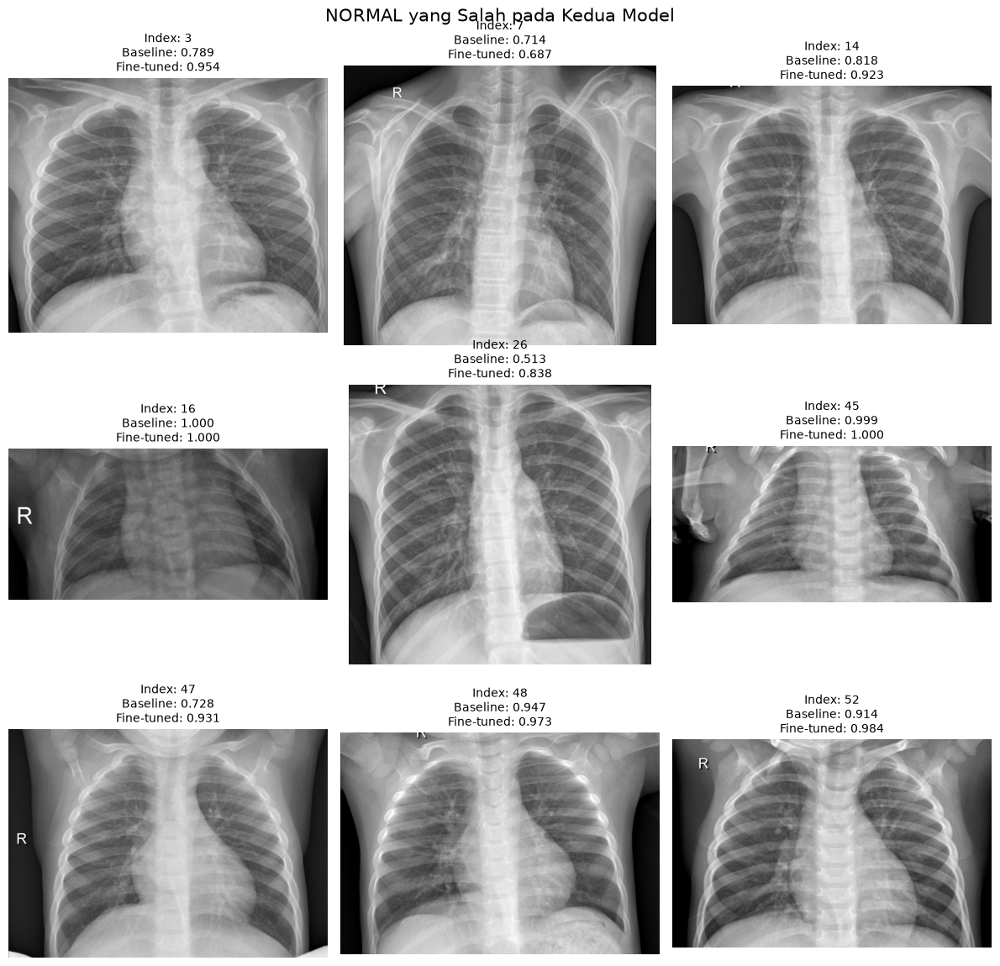

In [54]:

from PIL import Image
import matplotlib.pyplot as plt

def show_common_false_positives(indices, max_images=9):
    selected = indices[:max_images]

    if len(selected) == 0:
        print("Tidak ada false positive bersama.")
        return

    fig, axes = plt.subplots(3, 3, figsize=(12, 12))
    axes = axes.flatten()

    for ax in axes:
        ax.axis("off")

    for ax, idx in zip(axes, selected):
        with Image.open(test_images[idx]) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(
            f"Index: {idx}\n"
            f"Baseline: {y_prob_base_test[idx]:.3f}\n"
            f"Fine-tuned: {y_prob_ft_new[idx]:.3f}",
            fontsize=10
        )
        ax.axis("off")

    fig.suptitle(
        "NORMAL yang Salah pada Kedua Model",
        fontsize=15
    )
    plt.tight_layout()
    plt.show()

show_common_false_positives(common_fp)


Indeks gambar: 3
Label sebenarnya: NORMAL
Path gambar: D:\Lung disease detection\data\chest_xray\chest_xray\test\NORMAL\IM-0006-0001.jpeg


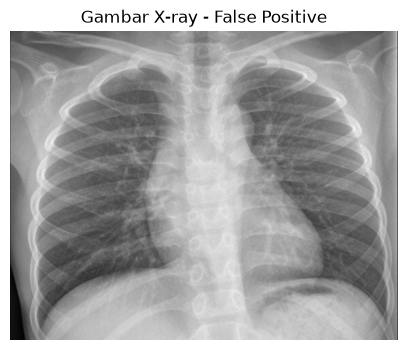

In [55]:

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

from PIL import Image
from torchvision import models
from pathlib import Path

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PROJECT_DIR = Path(r"D:\Lung disease detection")
baseline_path = PROJECT_DIR / "models" / "densenet121_baseline.pth"
finetuned_path = PROJECT_DIR / "models" / "densenet121_finetuned_best.pth"

# Gunakan gambar NORMAL yang salah pada kedua model
sample_idx = 3
image_path = test_images[sample_idx]

print("Indeks gambar:", sample_idx)
print("Label sebenarnya:", test_labels[sample_idx])
print("Path gambar:", image_path)

# Tampilkan gambar asli
with Image.open(image_path) as img:
    plt.figure(figsize=(5, 5))
    plt.imshow(img.convert("RGB"), cmap="gray")
    plt.title("Gambar X-ray - False Positive")
    plt.axis("off")
    plt.show()


In [56]:

def load_densenet_checkpoint(checkpoint_path):
    model = models.densenet121(weights=None)
    model.classifier = torch.nn.Linear(
        model.classifier.in_features, 2
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
    model.load_state_dict(checkpoint["model_state_dict"])
    model = model.to(device)
    model.eval()

    return model


def generate_gradcam(model, input_tensor, target_class=1):
    activations = []
    gradients = []

    target_layer = model.features.denseblock4

    def forward_hook(module, inputs, output):
        activations.append(output)

    def backward_hook(module, grad_input, grad_output):
        gradients.append(grad_output[0])

    forward_handle = target_layer.register_forward_hook(forward_hook)
    backward_handle = target_layer.register_full_backward_hook(backward_hook)

    model.zero_grad(set_to_none=True)

    output = model(input_tensor)
    score = output[:, target_class].sum()
    score.backward()

    activation = activations[0]
    gradient = gradients[0]

    weights = gradient.mean(dim=(2, 3), keepdim=True)
    cam = (weights * activation).sum(dim=1, keepdim=True)
    cam = F.relu(cam)

    cam = F.interpolate(
        cam,
        size=input_tensor.shape[2:],
        mode="bilinear",
        align_corners=False
    )

    cam = cam[0, 0].detach().cpu().numpy()
    cam = cam - cam.min()

    if cam.max() > 0:
        cam = cam / cam.max()

    forward_handle.remove()
    backward_handle.remove()

    return output.detach(), cam


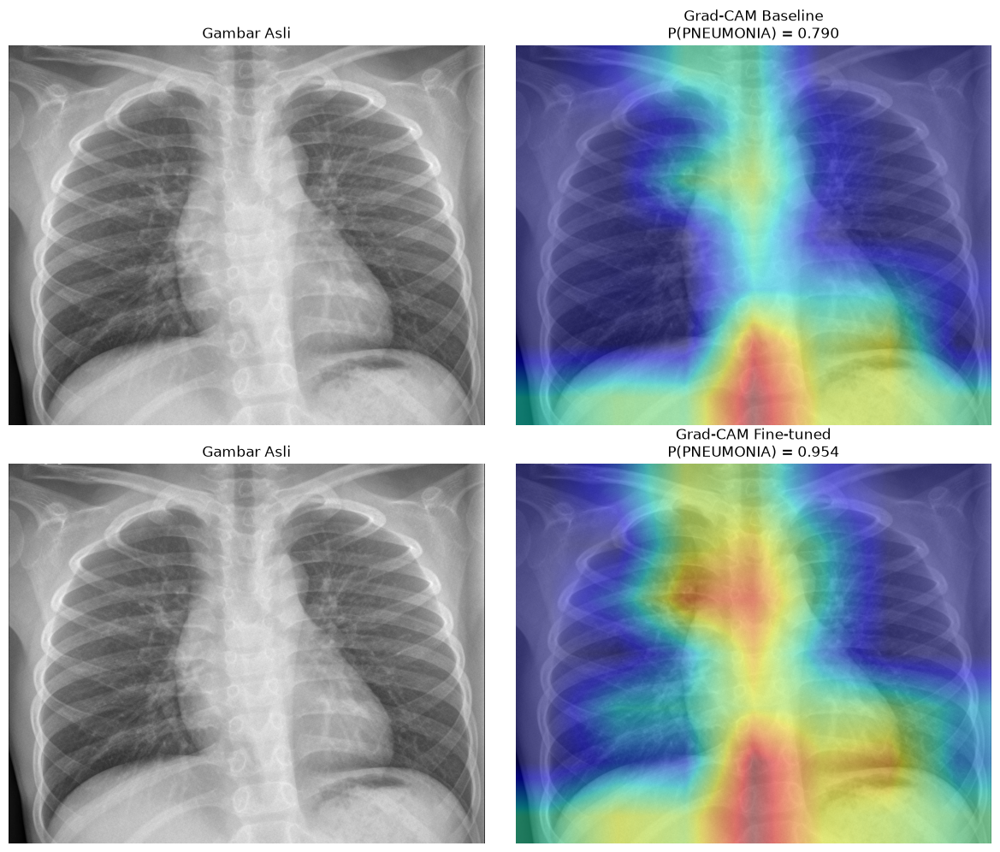

In [57]:

# Gunakan transformasi test yang sama dengan evaluasi sebelumnya
with Image.open(image_path) as img:
    input_tensor = test_transform(img.convert("RGB")).unsqueeze(0).to(device)

baseline_model = load_densenet_checkpoint(baseline_path)
finetuned_model = load_densenet_checkpoint(finetuned_path)

baseline_output, baseline_cam = generate_gradcam(
    baseline_model, input_tensor, target_class=1
)

finetuned_output, finetuned_cam = generate_gradcam(
    finetuned_model, input_tensor, target_class=1
)

baseline_prob = torch.softmax(baseline_output, dim=1)[0, 1].item()
finetuned_prob = torch.softmax(finetuned_output, dim=1)[0, 1].item()

with Image.open(image_path) as img:
    original_image = np.array(img.convert("RGB"))

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].imshow(original_image)
axes[0, 0].set_title("Gambar Asli")
axes[0, 0].axis("off")

axes[0, 1].imshow(original_image)
axes[0, 1].imshow(
    baseline_cam, cmap="jet", alpha=0.45,
    extent=(0, original_image.shape[1], original_image.shape[0], 0)
)
axes[0, 1].set_title(
    f"Grad-CAM Baseline\nP(PNEUMONIA) = {baseline_prob:.3f}"
)
axes[0, 1].axis("off")

axes[1, 0].imshow(original_image)
axes[1, 0].set_title("Gambar Asli")
axes[1, 0].axis("off")

axes[1, 1].imshow(original_image)
axes[1, 1].imshow(
    finetuned_cam, cmap="jet", alpha=0.45,
    extent=(0, original_image.shape[1], original_image.shape[0], 0)
)
axes[1, 1].set_title(
    f"Grad-CAM Fine-tuned\nP(PNEUMONIA) = {finetuned_prob:.3f}"
)
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()


In [58]:

import numpy as np

# Pastikan variabel berikut berasal dari evaluasi test terbaru:
# y_true_ft_new = label sebenarnya
# y_pred_ft_new = prediksi fine-tuned
# y_prob_ft_new = probabilitas PNEUMONIA fine-tuned

# Kelompok 1: NORMAL salah diprediksi sebagai PNEUMONIA
false_positive_idx = np.where(
    (y_true_ft_new == 0) & (y_pred_ft_new == 1)
)[0]

# Kelompok 2: PNEUMONIA diprediksi benar
true_positive_idx = np.where(
    (y_true_ft_new == 1) & (y_pred_ft_new == 1)
)[0]

# Ambil maksimal 10 gambar dari masing-masing kelompok
audit_fp = false_positive_idx[:10]
audit_tp = true_positive_idx[:10]

audit_indices = np.concatenate([audit_fp, audit_tp])

print("False positive yang diaudit:", len(audit_fp))
print("True positive yang diaudit:", len(audit_tp))
print("Total gambar audit:", len(audit_indices))
print("Indeks gambar:", audit_indices.tolist())


False positive yang diaudit: 10
True positive yang diaudit: 10
Total gambar audit: 20
Indeks gambar: [0, 3, 7, 11, 14, 16, 21, 26, 40, 44, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243]


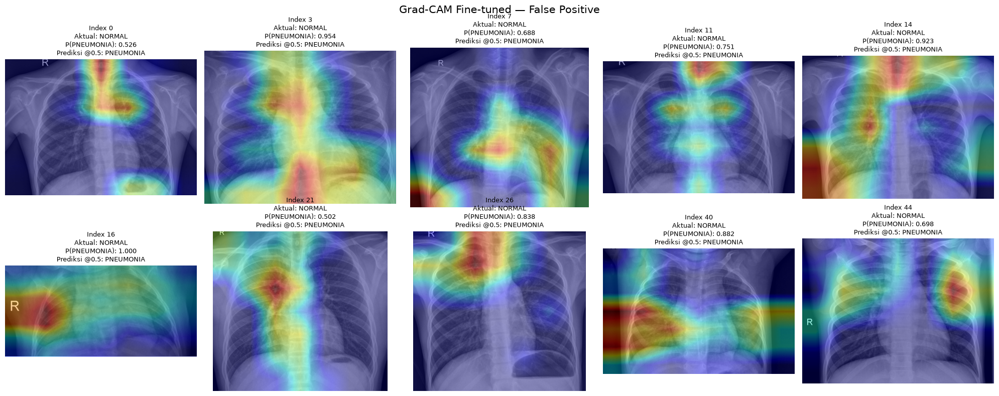

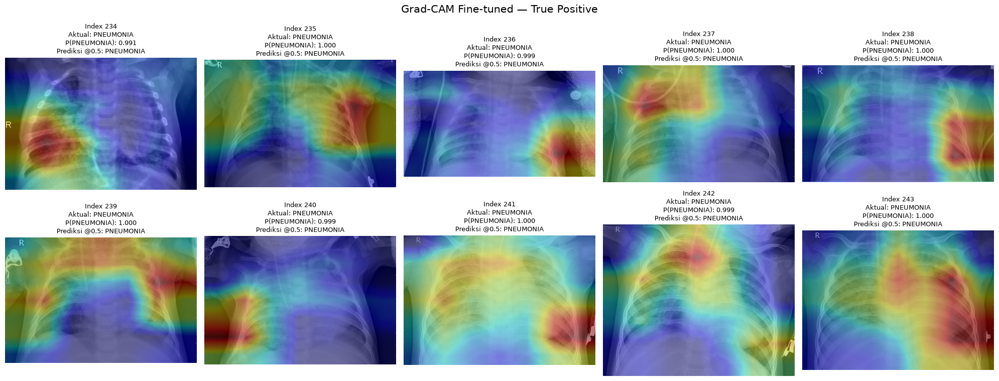

In [59]:

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

def audit_gradcam_grid(indices, title, model, max_cols=5):
    if len(indices) == 0:
        print("Tidak ada sampel untuk:", title)
        return

    n = len(indices)
    ncols = min(max_cols, n)
    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(4 * ncols, 4 * nrows)
    )
    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax, idx in zip(axes, indices):
        image_path = test_images[int(idx)]

        with Image.open(image_path) as img:
            original = img.convert("RGB")
            original_array = np.array(original)
            input_tensor = test_transform(original).unsqueeze(0).to(device)

        output, cam = generate_gradcam(
            model,
            input_tensor,
            target_class=1
        )

        probability = torch.softmax(output, dim=1)[0, 1].item()

        ax.imshow(original_array)
        ax.imshow(
            cam,
            cmap="jet",
            alpha=0.4,
            extent=(
                0, original_array.shape[1],
                original_array.shape[0], 0
            )
        )

        actual = "NORMAL" if y_true_ft_new[idx] == 0 else "PNEUMONIA"
        predicted = "PNEUMONIA" if probability >= 0.5 else "NORMAL"

        ax.set_title(
            f"Index {idx}\n"
            f"Aktual: {actual}\n"
            f"P(PNEUMONIA): {probability:.3f}\n"
            f"Prediksi @0.5: {predicted}",
            fontsize=9
        )
        ax.axis("off")

    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()


# Muat checkpoint fine-tuned terbaik
finetuned_model = load_densenet_checkpoint(finetuned_path)

# Kelompok 1: false positive
audit_gradcam_grid(
    audit_fp,
    "Grad-CAM Fine-tuned — False Positive",
    finetuned_model
)

# Kelompok 2: true positive
audit_gradcam_grid(
    audit_tp,
    "Grad-CAM Fine-tuned — True Positive",
    finetuned_model
)


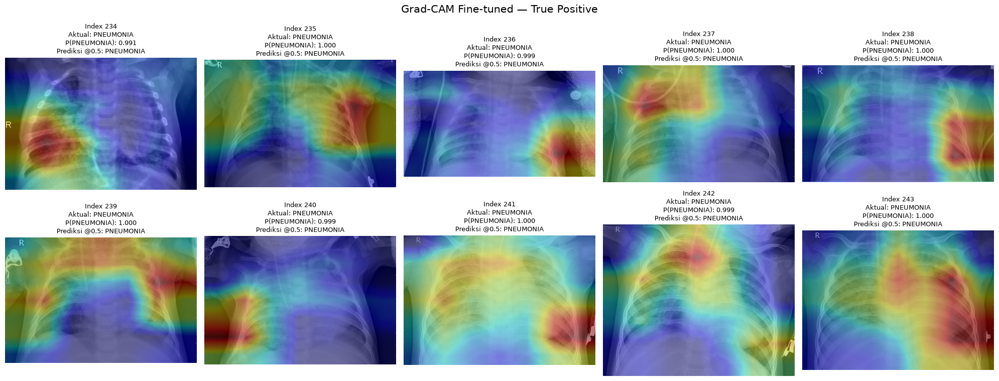

In [60]:

# Visualisasi 10 gambar True Positive
audit_gradcam_grid(
    audit_tp,
    "Grad-CAM Fine-tuned — True Positive",
    finetuned_model
)


In [61]:

import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def predict_pneumonia_probability(model, image_tensor):
    model.eval()
    with torch.no_grad():
        output = model(image_tensor.to(device))
        probability = torch.softmax(output, dim=1)[0, 1].item()
    return probability

def occlude_region(image, box, fill_value=0):
    """
    image: gambar RGB dalam bentuk NumPy array.
    box: (x1, y1, x2, y2), koordinat piksel.
    """
    result = image.copy()
    x1, y1, x2, y2 = box
    result[y1:y2, x1:x2] = fill_value
    return result

print("Fungsi occlusion berhasil disiapkan.")


Fungsi occlusion berhasil disiapkan.


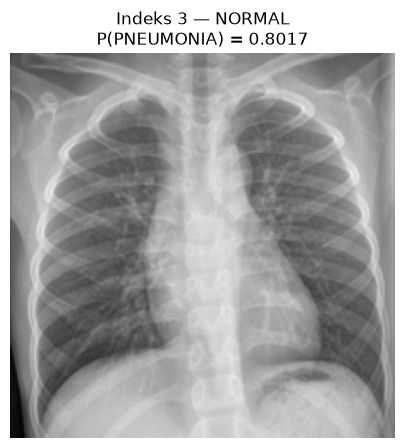

Probabilitas gambar asli: 0.8017


In [62]:

# Indeks 3 merupakan salah satu false positive baseline
# dan juga false positive fine-tuned.

sample_idx = 3
sample_path = test_images[sample_idx]

with Image.open(sample_path) as img:
    original_image = np.array(img.convert("RGB").resize((224, 224)))

# Probabilitas pada gambar asli
original_tensor = test_transform(
    Image.fromarray(original_image)
).unsqueeze(0)

original_prob = predict_pneumonia_probability(
    finetuned_model, original_tensor
)

plt.figure(figsize=(5, 5))
plt.imshow(original_image)
plt.title(
    f"Indeks {sample_idx} — NORMAL\n"
    f"P(PNEUMONIA) = {original_prob:.4f}"
)
plt.axis("off")
plt.show()

print(f"Probabilitas gambar asli: {original_prob:.4f}")


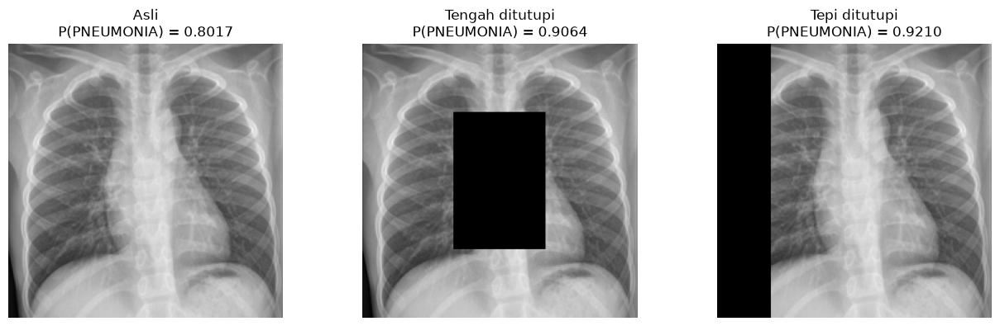

Probabilitas asli          : 0.8017
Perubahan setelah menutup tengah: +0.1047
Perubahan setelah menutup tepi  : +0.1193


In [63]:

# Pastikan gambar asli berukuran 224 x 224
H, W, _ = original_image.shape

# Buat tiga kondisi
experiments = {
    "Asli": original_image.copy(),
    "Tengah ditutupi": occlude_region(
        original_image,
        (W // 3, H // 4, 2 * W // 3, 3 * H // 4),
        fill_value=0
    ),
    "Tepi ditutupi": occlude_region(
        original_image,
        (0, 0, W // 5, H),
        fill_value=0
    )
}

results = {}

for name, image_array in experiments.items():
    image_pil = Image.fromarray(image_array)
    tensor = test_transform(image_pil).unsqueeze(0)

    probability = predict_pneumonia_probability(
        finetuned_model, tensor
    )
    results[name] = probability

# Visualisasi
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, (name, image_array) in zip(axes, experiments.items()):
    ax.imshow(image_array)
    ax.set_title(
        f"{name}\nP(PNEUMONIA) = {results[name]:.4f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

print(f"Probabilitas asli          : {results['Asli']:.4f}")
print(
    "Perubahan setelah menutup tengah: "
    f"{results['Tengah ditutupi'] - results['Asli']:+.4f}"
)
print(
    "Perubahan setelah menutup tepi  : "
    f"{results['Tepi ditutupi'] - results['Asli']:+.4f}"
)


In [64]:

H, W, _ = original_image.shape

regions = {
    "Asli": None,
    "Kiri": (0, 0, W // 3, H),
    "Kanan": (2 * W // 3, 0, W, H),
    "Atas": (0, 0, W, H // 3),
    "Bawah": (0, 2 * H // 3, W, H),
    "Tengah": (W // 3, H // 4, 2 * W // 3, 3 * H // 4),
}

region_results = {}

for name, box in regions.items():
    if box is None:
        test_image = original_image.copy()
    else:
        test_image = occlude_region(
            original_image, box, fill_value=0
        )

    tensor = test_transform(
        Image.fromarray(test_image)
    ).unsqueeze(0)

    prob = predict_pneumonia_probability(
        finetuned_model, tensor
    )

    region_results[name] = prob

print("Hasil uji occlusion:")
for name, prob in region_results.items():
    delta = prob - region_results["Asli"]
    print(
        f"{name:8s} | P(PNEUMONIA)={prob:.4f} "
        f"| perubahan={delta:+.4f}"
    )


Hasil uji occlusion:
Asli     | P(PNEUMONIA)=0.8017 | perubahan=+0.0000
Kiri     | P(PNEUMONIA)=0.7521 | perubahan=-0.0496
Kanan    | P(PNEUMONIA)=0.8701 | perubahan=+0.0684
Atas     | P(PNEUMONIA)=0.4369 | perubahan=-0.3648
Bawah    | P(PNEUMONIA)=0.8191 | perubahan=+0.0174
Tengah   | P(PNEUMONIA)=0.9064 | perubahan=+0.1047


In [65]:

def occlusion_test_one(image_array, model, transform, device):
    H, W, _ = image_array.shape

    regions = {
        "Asli": None,
        "Kiri": (0, 0, W // 3, H),
        "Kanan": (2 * W // 3, 0, W, H),
        "Atas": (0, 0, W, H // 3),
        "Bawah": (0, 2 * H // 3, W, H),
        "Tengah": (W // 3, H // 4, 2 * W // 3, 3 * H // 4),
    }

    probs = {}

    for name, box in regions.items():
        arr = (
            image_array.copy()
            if box is None
            else occlude_region(image_array, box, fill_value=0)
        )

        tensor = transform(Image.fromarray(arr)).unsqueeze(0)
        probs[name] = predict_pneumonia_probability(model, tensor)

    return {
        region: prob - probs["Asli"]
        for region, prob in probs.items()
        if region != "Asli"
    }

print("Fungsi pengujian multi-gambar siap.")


Fungsi pengujian multi-gambar siap.


In [66]:

import pandas as pd

audit_records = []

groups = {
    "False Positive": audit_fp,
    "True Positive": audit_tp
}

for group_name, indices in groups.items():
    for idx in indices:
        image_path = test_images[int(idx)]

        with Image.open(image_path) as img:
            image_array = np.array(
                img.convert("RGB").resize((224, 224))
            )

        changes = occlusion_test_one(
            image_array,
            finetuned_model,
            test_transform,
            device
        )

        record = {
            "index": int(idx),
            "group": group_name
        }
        record.update(changes)
        audit_records.append(record)

occlusion_df = pd.DataFrame(audit_records)

print("Hasil 20 gambar pertama:")
display(occlusion_df.round(4))

print("\nRata-rata perubahan probabilitas:")
summary_occlusion = (
    occlusion_df
    .groupby("group")[["Kiri", "Kanan", "Atas", "Bawah", "Tengah"]]
    .mean()
)
display(summary_occlusion.round(4))


Hasil 20 gambar pertama:


,index,group,Kiri,Kanan,Atas,Bawah,Tengah
0,0,False Positive,0.1121,0.4824,-0.3915,-0.1954,-0.0774
1,3,False Positive,-0.0496,0.0684,-0.3648,0.0174,0.1047
2,7,False Positive,0.0387,-0.0670,0.0265,-0.5205,0.0190
3,11,False Positive,-0.2961,0.1504,-0.6212,-0.1240,0.0411
4,14,False Positive,0.0171,0.0293,-0.0074,-0.4385,0.0310
5,16,False Positive,-0.0632,-0.0003,-0.0095,-0.0001,-0.0001
6,21,False Positive,0.1394,0.3095,-0.4230,0.2287,0.3195
7,26,False Positive,-0.5173,0.0999,-0.7422,-0.0224,-0.2023
8,40,False Positive,-0.6142,0.1713,0.1691,-0.6960,0.0160
9,44,False Positive,0.3274,0.4950,-0.2870,0.3124,0.4437



Rata-rata perubahan probabilitas:


,Kiri,Kanan,Atas,Bawah,Tengah
group,,,,,
False Positive,-0.0906,0.1739,-0.2651,-0.1438,0.0695
True Positive,-0.0428,-0.0002,-0.0377,-0.0493,0.0003


In [67]:

from PIL import Image, ImageFilter

def blur_region(image_array, box, radius=12):
    """
    Mengaburkan wilayah tertentu dan mempertahankan
    bagian gambar lainnya.
    """
    original = Image.fromarray(image_array)
    blurred = original.filter(
        ImageFilter.GaussianBlur(radius=radius)
    )

    mask = Image.new("L", original.size, 0)
    from PIL import ImageDraw
    draw = ImageDraw.Draw(mask)
    draw.rectangle(box, fill=255)

    result = Image.composite(blurred, original, mask)
    return np.array(result)

print("Fungsi blur occlusion siap digunakan.")


Fungsi blur occlusion siap digunakan.


In [68]:

blur_records = []

regions = {
    "Kiri": (0, 0, 224 // 3, 224),
    "Kanan": (2 * 224 // 3, 0, 224, 224),
    "Atas": (0, 0, 224, 224 // 3),
    "Bawah": (0, 2 * 224 // 3, 224, 224),
    "Tengah": (224 // 3, 224 // 4, 2 * 224 // 3, 3 * 224 // 4),
}

for group_name, indices in groups.items():
    for idx in indices:
        with Image.open(test_images[int(idx)]) as img:
            image_array = np.array(
                img.convert("RGB").resize((224, 224))
            )

        original_tensor = test_transform(
            Image.fromarray(image_array)
        ).unsqueeze(0)

        original_prob = predict_pneumonia_probability(
            finetuned_model, original_tensor
        )

        for region_name, box in regions.items():
            # Black occlusion
            black_image = occlude_region(
                image_array, box, fill_value=0
            )
            black_tensor = test_transform(
                Image.fromarray(black_image)
            ).unsqueeze(0)

            black_prob = predict_pneumonia_probability(
                finetuned_model, black_tensor
            )

            # Blur occlusion
            blurred_image = blur_region(
                image_array, box, radius=12
            )
            blur_tensor = test_transform(
                Image.fromarray(blurred_image)
            ).unsqueeze(0)

            blur_prob = predict_pneumonia_probability(
                finetuned_model, blur_tensor
            )

            blur_records.append({
                "index": int(idx),
                "group": group_name,
                "region": region_name,
                "black_delta": black_prob - original_prob,
                "blur_delta": blur_prob - original_prob
            })

blur_df = pd.DataFrame(blur_records)

summary_blur = (
    blur_df.groupby(["group", "region"])[
        ["black_delta", "blur_delta"]
    ]
    .mean()
    .round(4)
)

display(summary_blur)


black_delta  blur_delta
group          region                         
False Positive Atas        -0.2651      0.0569
               Bawah       -0.1438      0.1944
               Kanan        0.1739      0.1861
               Kiri        -0.0906      0.1558
               Tengah       0.0695     -0.0597
True Positive  Atas        -0.0377     -0.0032
               Bawah       -0.0493     -0.0045
               Kanan       -0.0002     -0.0002
               Kiri        -0.0428     -0.0024
               Tengah       0.0003     -0.0347

In [69]:
import torch
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score

# Muat kedua checkpoint
baseline_model = load_densenet_checkpoint(
    r"D:\Lung disease detection\models\densenet121_baseline.pth"
)

finetuned_model = load_densenet_checkpoint(
    r"D:\Lung disease detection\models\densenet121_finetuned_best.pth"
)

# Prediksi pada validation set yang sama
y_val_true_base, y_val_base_pred, y_val_base_prob = predict_loader(
    baseline_model, val_loader, device
)

y_val_true_ft, y_val_ft_pred, y_val_ft_prob = predict_loader(
    finetuned_model, val_loader, device
)

# Pastikan label validation kedua model sama
assert np.array_equal(y_val_true_base, y_val_true_ft), \
    "Urutan label validation berbeda!"

# Ringkasan evaluasi
for name, y_pred, y_prob in [
    ("Baseline", y_val_base_pred, y_val_base_prob),
    ("Fine-tuned", y_val_ft_pred, y_val_ft_prob)
]:
    print(f"\n===== {name} =====")
    print("Confusion Matrix:")
    print(confusion_matrix(y_val_true_base, y_pred))
    print(f"Accuracy : {accuracy_score(y_val_true_base, y_pred):.4f}")
    print(f"ROC-AUC  : {roc_auc_score(y_val_true_base, y_prob):.4f}")

    # Label 0 = NORMAL, label 1 = PNEUMONIA
    normal_prob = y_prob[y_val_true_base == 0]
    pneumonia_prob = y_prob[y_val_true_base == 1]

    print(f"Rata-rata P(PNEUMONIA) pada NORMAL    : {normal_prob.mean():.4f}")
    print(f"Median P(PNEUMONIA) pada NORMAL       : {np.median(normal_prob):.4f}")
    print(f"Rata-rata P(PNEUMONIA) pada PNEUMONIA : {pneumonia_prob.mean():.4f}")
    print(f"Median P(PNEUMONIA) pada PNEUMONIA    : {np.median(pneumonia_prob):.4f}")


===== Baseline =====
Confusion Matrix:
[[261   7]
 [ 45 731]]
Accuracy : 0.9502
ROC-AUC  : 0.9930
Rata-rata P(PNEUMONIA) pada NORMAL    : 0.0524
Median P(PNEUMONIA) pada NORMAL       : 0.0080
Rata-rata P(PNEUMONIA) pada PNEUMONIA : 0.9241
Median P(PNEUMONIA) pada PNEUMONIA    : 0.9958

===== Fine-tuned =====
Confusion Matrix:
[[263   5]
 [ 23 753]]
Accuracy : 0.9732
ROC-AUC  : 0.9967
Rata-rata P(PNEUMONIA) pada NORMAL    : 0.0407
Median P(PNEUMONIA) pada NORMAL       : 0.0042
Rata-rata P(PNEUMONIA) pada PNEUMONIA : 0.9602
Median P(PNEUMONIA) pada PNEUMONIA    : 0.9994


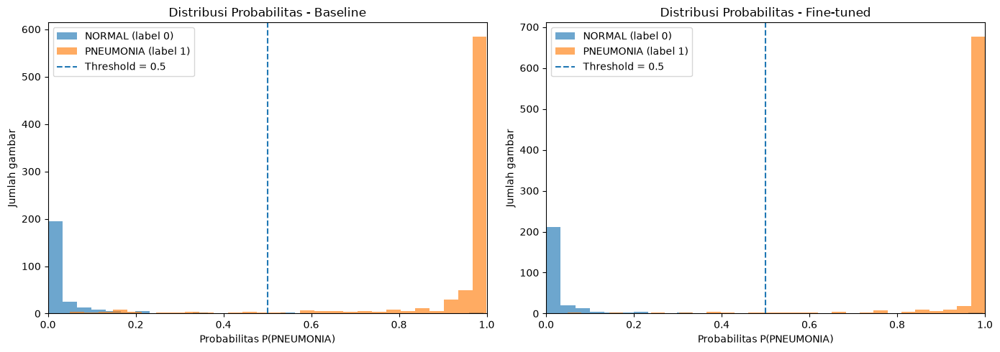

In [70]:
import matplotlib.pyplot as plt
import numpy as np

# Pisahkan probabilitas berdasarkan label sebenarnya
normal_mask = y_val_true_base == 0
pneumonia_mask = y_val_true_base == 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models_data = [
    (
        "Baseline",
        y_val_base_prob
    ),
    (
        "Fine-tuned",
        y_val_ft_prob
    )
]

for ax, (model_name, probabilities) in zip(axes, models_data):
    ax.hist(
        probabilities[normal_mask],
        bins=30,
        alpha=0.65,
        label="NORMAL (label 0)"
    )

    ax.hist(
        probabilities[pneumonia_mask],
        bins=30,
        alpha=0.65,
        label="PNEUMONIA (label 1)"
    )

    ax.axvline(
        0.5,
        linestyle="--",
        linewidth=1.5,
        label="Threshold = 0.5"
    )

    ax.set_title(f"Distribusi Probabilitas - {model_name}")
    ax.set_xlabel("Probabilitas P(PNEUMONIA)")
    ax.set_ylabel("Jumlah gambar")
    ax.set_xlim(0, 1)
    ax.legend()

plt.tight_layout()
plt.show()

In [71]:
import pandas as pd
import numpy as np

def confidence_summary(y_true, y_pred, y_prob, model_name):
    correct = y_true == y_pred

    return {
        "Model": model_name,
        "Rata-rata probabilitas saat benar": np.mean(
            np.where(y_true == 1, y_prob, 1 - y_prob)[correct]
        ),
        "Rata-rata probabilitas saat salah": np.mean(
            np.where(y_true == 1, y_prob, 1 - y_prob)[~correct]
        ),
        "Jumlah prediksi benar": int(correct.sum()),
        "Jumlah prediksi salah": int((~correct).sum())
    }

summary = pd.DataFrame([
    confidence_summary(
        y_val_true_base,
        y_val_base_pred,
        y_val_base_prob,
        "Baseline"
    ),
    confidence_summary(
        y_val_true_ft,
        y_val_ft_pred,
        y_val_ft_prob,
        "Fine-tuned"
    )
])

display(summary.round(4))

,Model,Rata-rata probabilitas saat benar,Rata-rata probabilitas saat salah,Jumlah prediksi benar,Jumlah prediksi salah
0,Baseline,0.9658,0.2499,992,52
1,Fine-tuned,0.9787,0.2816,1016,28


In [72]:
import pandas as pd
import numpy as np

def error_confidence_summary(y_true, y_pred, y_prob, model_name):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_prob = np.asarray(y_prob)

    # False Positive: NORMAL diprediksi PNEUMONIA
    fp = (y_true == 0) & (y_pred == 1)

    # False Negative: PNEUMONIA diprediksi NORMAL
    fn = (y_true == 1) & (y_pred == 0)

    return [
        {
            "Model": model_name,
            "Jenis kesalahan": "False Positive",
            "Jumlah": int(fp.sum()),
            "Rata-rata P(PNEUMONIA)": (
                y_prob[fp].mean() if fp.any() else np.nan
            ),
            "Confidence kelas salah": (
                y_prob[fp].mean() if fp.any() else np.nan
            )
        },
        {
            "Model": model_name,
            "Jenis kesalahan": "False Negative",
            "Jumlah": int(fn.sum()),
            "Rata-rata P(PNEUMONIA)": (
                y_prob[fn].mean() if fn.any() else np.nan
            ),
            "Confidence kelas salah": (
                (1 - y_prob[fn]).mean() if fn.any() else np.nan
            )
        }
    ]

results = []

results.extend(error_confidence_summary(
    y_val_true_base,
    y_val_base_pred,
    y_val_base_prob,
    "Baseline"
))

results.extend(error_confidence_summary(
    y_val_true_ft,
    y_val_ft_pred,
    y_val_ft_prob,
    "Fine-tuned"
))

display(pd.DataFrame(results).round(4))

,Model,Jenis kesalahan,Jumlah,Rata-rata P(PNEUMONIA),Confidence kelas salah
0,Baseline,False Positive,7,0.7313,0.7313
1,Baseline,False Negative,45,0.2469,0.7531
2,Fine-tuned,False Positive,5,0.8552,0.8552
3,Fine-tuned,False Negative,23,0.3114,0.6886


In [73]:
import numpy as np
import pandas as pd

def test_probability_summary(y_true, y_prob, model_name):
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    normal_prob = y_prob[y_true == 0]
    pneumonia_prob = y_prob[y_true == 1]

    return {
        "Model": model_name,
        "Rata-rata P(PNEUMONIA) pada NORMAL": normal_prob.mean(),
        "Median P(PNEUMONIA) pada NORMAL": np.median(normal_prob),
        "Persentil ke-90 NORMAL": np.percentile(normal_prob, 90),
        "NORMAL dengan P(PNEUMONIA) >= 0.5": int(
            (normal_prob >= 0.5).sum()
        ),
        "Rata-rata P(PNEUMONIA) pada PNEUMONIA": pneumonia_prob.mean(),
        "Median P(PNEUMONIA) pada PNEUMONIA": np.median(pneumonia_prob)
    }

test_summary = pd.DataFrame([
    test_probability_summary(
        y_true_base_test,
        y_prob_base_test,
        "Baseline"
    ),
    test_probability_summary(
        y_true_ft_new,
        y_prob_ft_new,
        "Fine-tuned"
    )
])

display(test_summary.round(4))

,Model,Rata-rata P(PNEUMONIA) pada NORMAL,Median P(PNEUMONIA) pada NORMAL,Persentil ke-90 NORMAL,NORMAL dengan P(PNEUMONIA) >= 0.5,Rata-rata P(PNEUMONIA) pada PNEUMONIA,Median P(PNEUMONIA) pada PNEUMONIA
0,Baseline,0.3272,0.1663,0.9235,68,0.9548,0.9967
1,Fine-tuned,0.4151,0.2687,0.9805,95,0.9825,0.9995


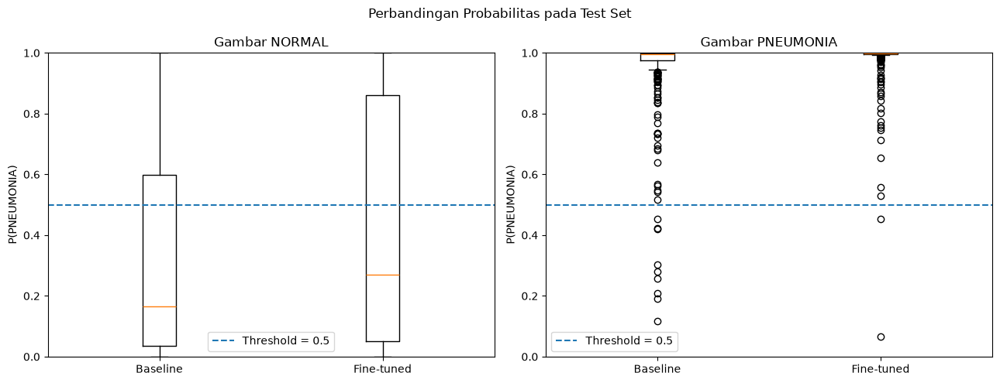

In [74]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

models = [
    ("Baseline", y_prob_base_test),
    ("Fine-tuned", y_prob_ft_new)
]

# Grafik 1: probabilitas pada gambar NORMAL
normal_data = [
    prob[np.asarray(y_true_base_test) == 0]
    for _, prob in models
]

axes[0].boxplot(
    normal_data,
    tick_labels=["Baseline", "Fine-tuned"],
    showfliers=True
)
axes[0].set_title("Gambar NORMAL")
axes[0].set_ylabel("P(PNEUMONIA)")
axes[0].set_ylim(0, 1)
axes[0].axhline(0.5, linestyle="--", label="Threshold = 0.5")
axes[0].legend()

# Grafik 2: probabilitas pada gambar PNEUMONIA
pneumonia_data = [
    prob[np.asarray(y_true_base_test) == 1]
    for _, prob in models
]

axes[1].boxplot(
    pneumonia_data,
    tick_labels=["Baseline", "Fine-tuned"],
    showfliers=True
)
axes[1].set_title("Gambar PNEUMONIA")
axes[1].set_ylabel("P(PNEUMONIA)")
axes[1].set_ylim(0, 1)
axes[1].axhline(0.5, linestyle="--", label="Threshold = 0.5")
axes[1].legend()

plt.suptitle("Perbandingan Probabilitas pada Test Set")
plt.tight_layout()
plt.show()

Jumlah False Positive baru: 28
Indeks: [  0  11  21  40  44  59  66  71  80  99 103 109]


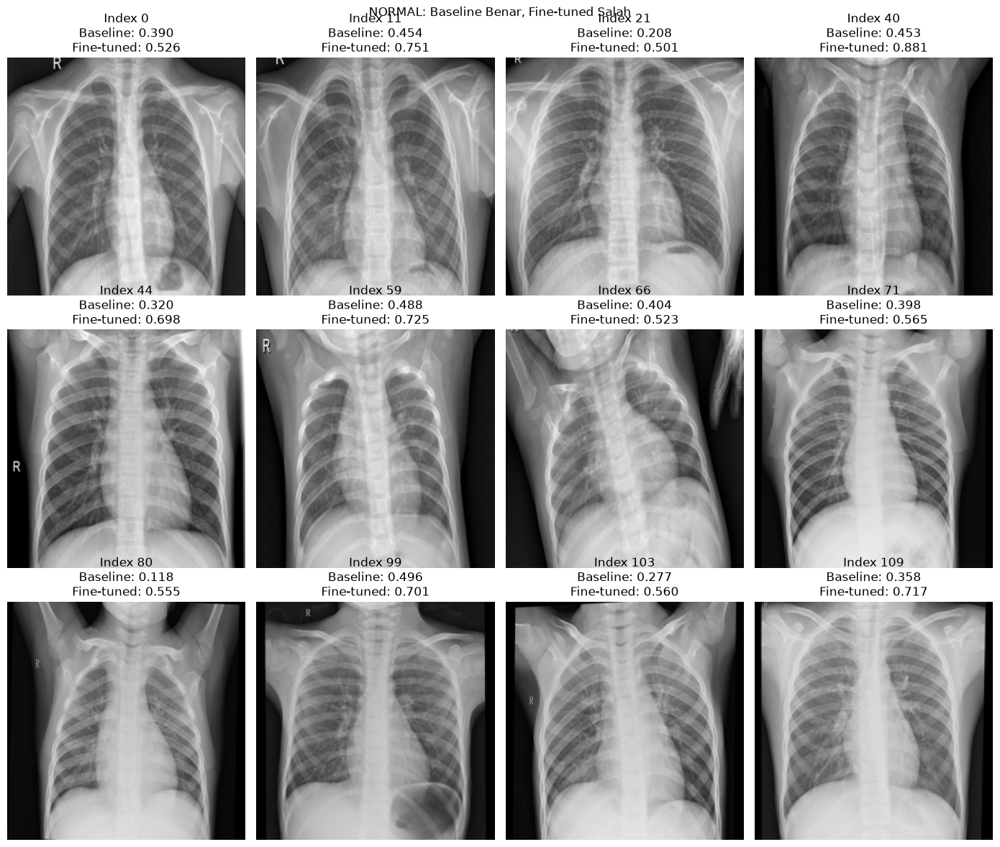

In [75]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

y_true = np.asarray(y_true_base_test)
base_pred = np.asarray(y_pred_base_test)
ft_pred = np.asarray(y_pred_ft_new)

# Gambar NORMAL yang benar di baseline,
# tetapi menjadi False Positive di fine-tuned
new_false_positives = np.where(
    (y_true == 0) &
    (base_pred == 0) &
    (ft_pred == 1)
)[0]

print("Jumlah False Positive baru:", len(new_false_positives))
print("Indeks:", new_false_positives[:12])

# Tampilkan maksimal 12 gambar
selected_indices = new_false_positives[:12]

if len(selected_indices) > 0:
    cols = 4
    rows = int(np.ceil(len(selected_indices) / cols))

    fig, axes = plt.subplots(
        rows, cols,
        figsize=(14, 4 * rows)
    )
    axes = np.array(axes).reshape(-1)

    for ax, idx in zip(axes, selected_indices):
        img = Image.open(test_images[idx]).convert("RGB")
        img = img.resize((224, 224))

        ax.imshow(img)
        ax.set_title(
            f"Index {idx}\n"
            f"Baseline: {y_prob_base_test[idx]:.3f}\n"
            f"Fine-tuned: {y_prob_ft_new[idx]:.3f}"
        )
        ax.axis("off")

    for ax in axes[len(selected_indices):]:
        ax.axis("off")

    plt.suptitle(
        "NORMAL: Baseline Benar, Fine-tuned Salah"
    )
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ditemukan False Positive baru.")

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

y_true = np.asarray(y_true_base_test)
base_prob = np.asarray(y_prob_base_test)
ft_prob = np.asarray(y_prob_ft_new)

normal_mask = y_true == 0

# Ambil probabilitas dari semua gambar NORMAL
normal_base = base_prob[normal_mask]
normal_ft = ft_prob[normal_mask]

# Perubahan skor: fine-tuned dikurangi baseline
delta = normal_ft - normal_base

print("Jumlah gambar NORMAL:", len(delta))
print(f"Rata-rata perubahan probabilitas: {delta.mean():+.4f}")
print(f"Median perubahan probabilitas  : {np.median(delta):+.4f}")
print(f"Skor meningkat                 : {(delta > 0).sum()}")
print(f"Skor menurun                   : {(delta < 0).sum()}")
print(f"Skor tidak berubah             : {(delta == 0).sum()}")

# Visualisasi perubahan probabilitas
plt.figure(figsize=(9, 5))
plt.hist(delta, bins=30, edgecolor="black")
plt.axvline(0, linestyle="--", label="Tidak ada perubahan")
plt.xlabel("Perubahan P(PNEUMONIA): Fine-tuned - Baseline")
plt.ylabel("Jumlah gambar")
plt.title("Pergeseran Probabilitas pada Gambar NORMAL")
plt.legend()
plt.tight_layout()
plt.show()

NameError: name 'y_true_base_test' is not defined

In [1]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score

# Lokasi proyek
PROJECT_DIR = Path(r"D:\Lung disease detection")
MODEL_DIR = PROJECT_DIR / "models"

# Periksa checkpoint
baseline_path = MODEL_DIR / "densenet121_baseline.pth"
finetuned_path = MODEL_DIR / "densenet121_finetuned_best.pth"

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA tersedia:", torch.cuda.is_available())
print("Baseline tersedia:", baseline_path.exists())
print("Fine-tuned tersedia:", finetuned_path.exists())

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
CUDA tersedia: True
Baseline tersedia: True
Fine-tuned tersedia: True


In [2]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def load_densenet_checkpoint(checkpoint_path):
    model = models.densenet121(weights=None)
    model.classifier = nn.Linear(model.classifier.in_features, 2)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    # Mendukung checkpoint berupa dictionary maupun state_dict langsung
    state_dict = checkpoint.get("model_state_dict", checkpoint)

    model.load_state_dict(state_dict)
    model = model.to(device)
    model.eval()

    return model

baseline_model = load_densenet_checkpoint(baseline_path)
finetuned_model = load_densenet_checkpoint(finetuned_path)

print("Device:", device)
print("Baseline berhasil dimuat:", type(baseline_model).__name__)
print("Fine-tuned berhasil dimuat:", type(finetuned_model).__name__)

Device: cuda
Baseline berhasil dimuat: DenseNet
Fine-tuned berhasil dimuat: DenseNet


In [3]:
print("val_loader tersedia:", "val_loader" in globals())
print("test_loader tersedia:", "test_loader" in globals())
print("predict_loader tersedia:", "predict_loader" in globals())
print("test_images tersedia:", "test_images" in globals())

val_loader tersedia: False
test_loader tersedia: False
predict_loader tersedia: False
test_images tersedia: False


In [4]:
from pathlib import Path
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Lokasi dataset
DATA_DIR = Path(
    r"D:\Lung disease detection\data\chest_xray\chest_xray"
)

TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"

# Transformasi harus sama dengan evaluasi model sebelumnya
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Dataset test
test_dataset = datasets.ImageFolder(
    root=TEST_DIR,
    transform=test_transform
)

# Pastikan label sesuai dengan model
print("Class mapping:", test_dataset.class_to_idx)
print("Jumlah gambar test:", len(test_dataset))

# DataLoader untuk inferensi
test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("Jumlah batch test:", len(test_loader))
print("Dataset dan DataLoader siap.")

Class mapping: {'NORMAL': 0, 'PNEUMONIA': 1}
Jumlah gambar test: 624
Jumlah batch test: 39
Dataset dan DataLoader siap.


In [5]:
import numpy as np
import torch
from tqdm.auto import tqdm

def predict_loader(model, loader, device):
    model.eval()

    all_labels = []
    all_preds = []
    all_probs = []

    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Prediksi"):
            images = images.to(device)

            outputs = model(images)
            probabilities = torch.softmax(outputs, dim=1)

            predictions = outputs.argmax(dim=1)

            all_labels.extend(labels.numpy())
            all_preds.extend(predictions.cpu().numpy())
            all_probs.extend(probabilities[:, 1].cpu().numpy())

    return (
        np.array(all_labels),
        np.array(all_preds),
        np.array(all_probs)
    )

print("Fungsi predict_loader siap.")

Fungsi predict_loader siap.


In [6]:
# Prediksi baseline
y_true_base_test, y_pred_base_test, y_prob_base_test = predict_loader(
    baseline_model, test_loader, device
)

# Prediksi fine-tuned
y_true_ft_new, y_pred_ft_new, y_prob_ft_new = predict_loader(
    finetuned_model, test_loader, device
)

print("\nJumlah prediksi baseline:", len(y_pred_base_test))
print("Jumlah prediksi fine-tuned:", len(y_pred_ft_new))

print(
    "Label kedua model sama:",
    np.array_equal(y_true_base_test, y_true_ft_new)
)

Prediksi:   0%|          | 0/39 [00:00<?, ?it/s]

Prediksi:   0%|          | 0/39 [00:00<?, ?it/s]


Jumlah prediksi baseline: 624
Jumlah prediksi fine-tuned: 624
Label kedua model sama: True


In [7]:
import numpy as np
from pathlib import Path

save_path = Path(
    r"D:\Lung disease detection\models\test_predictions.npz"
)

np.savez_compressed(
    save_path,
    y_true_base_test=y_true_base_test,
    y_pred_base_test=y_pred_base_test,
    y_prob_base_test=y_prob_base_test,
    y_true_ft_new=y_true_ft_new,
    y_pred_ft_new=y_pred_ft_new,
    y_prob_ft_new=y_prob_ft_new
)

print("Prediksi berhasil disimpan!")
print("Lokasi:", save_path)
print("Jumlah data:", len(y_true_base_test))
print("Ukuran file (KB):", round(save_path.stat().st_size / 1024, 2))

Prediksi berhasil disimpan!
Lokasi: D:\Lung disease detection\models\test_predictions.npz
Jumlah data: 624
Ukuran file (KB): 5.67


In [8]:

import numpy as np

# Muat ulang hasil prediksi yang sudah disimpan
save_path = r"D:\Lung disease detection\models\test_predictions.npz"
data = np.load(save_path)

y_true = data["y_true_base_test"]
prob_base = data["y_prob_base_test"]
prob_ft = data["y_prob_ft_new"]

# Ambil gambar yang label aslinya NORMAL (label = 0)
normal_mask = (y_true == 0)

normal_base = prob_base[normal_mask]
normal_ft = prob_ft[normal_mask]

print("ANALISIS PROBABILITAS PADA CITRA NORMAL")
print("=" * 45)
print(f"Jumlah citra NORMAL: {normal_mask.sum()}")
print()
print("Baseline:")
print(f"  Rata-rata probabilitas Pneumonia: {normal_base.mean():.4f}")
print(f"  Median probabilitas Pneumonia   : {np.median(normal_base):.4f}")
print(f"  Citra NORMAL diprediksi Pneumonia: {(normal_base >= 0.5).sum()}")
print()
print("Fine-tuned:")
print(f"  Rata-rata probabilitas Pneumonia: {normal_ft.mean():.4f}")
print(f"  Median probabilitas Pneumonia   : {np.median(normal_ft):.4f}")
print(f"  Citra NORMAL diprediksi Pneumonia: {(normal_ft >= 0.5).sum()}")
print()
print("Perubahan rata-rata probabilitas:",
      f"{normal_ft.mean() - normal_base.mean():+.4f}")


ANALISIS PROBABILITAS PADA CITRA NORMAL
Jumlah citra NORMAL: 234

Baseline:
  Rata-rata probabilitas Pneumonia: 0.3272
  Median probabilitas Pneumonia   : 0.1663
  Citra NORMAL diprediksi Pneumonia: 68

Fine-tuned:
  Rata-rata probabilitas Pneumonia: 0.4151
  Median probabilitas Pneumonia   : 0.2687
  Citra NORMAL diprediksi Pneumonia: 95

Perubahan rata-rata probabilitas: +0.0879


In [9]:

variabel_validasi = [
    "y_true_base_val",
    "y_prob_base_val",
    "y_true_ft_val",
    "y_prob_ft_val"
]

for nama in variabel_validasi:
    print(f"{nama}: {'tersedia' if nama in globals() else 'belum tersedia'}")


y_true_base_val: belum tersedia
y_prob_base_val: belum tersedia
y_true_ft_val: belum tersedia
y_prob_ft_val: belum tersedia
